# Fantasy Football in the Brasileirão: previsão de pontos e escalação no Cartola FC
Autor: [nome do autor]

Disciplina: Inteligência Artificial (Ciência da Computação, UFPI)

Professor: Dr. Pedro Almir Martins de Oliveira

---

# 1. Identificação do projeto

Objetivo: prever quantos pontos cada atleta fará na próxima rodada do Cartola FC e usar essas previsões para montar a melhor escalação possível dentro do orçamento disponível.

Pergunta de pesquisa: um modelo de aprendizado de máquina, treinado apenas com os dados públicos do Cartola, consegue escalar times que pontuam mais do que um critério simples usado por jogadores comuns, que é escalar os atletas de maior média?

Tipo de aprendizado: supervisionado (regressão com LightGBM), combinado com otimização por programação inteira para escolher a escalação.

Dados: https://github.com/henriquepgomide/caRtola e https://www.football-data.co.uk/brazil.php

Código: https://github.com/S0breira/Machine-Learning-for-Fantasy-Football-Predicting-Player-Scores-and-Optimizing-Lineups-in-Cartola-FC

# 2. Descrição do problema
O Cartola FC é o fantasy game oficial do Campeonato Brasileiro. A cada rodada, o jogador escala 11 atletas e um técnico em uma das formações permitidas (3-4-3, 3-5-2, 4-3-3, 4-4-2, 4-5-1, 5-3-2 ou 5-4-1), escolhe um capitão, que tem a pontuação multiplicada, e precisa respeitar um orçamento em cartoletas, que começa em C$ 100. Também pode indicar reservas, que entram no lugar dos titulares que não jogarem, e, desde 2025, um Reserva de Luxo, que pode substituir o titular da posição que pontuar menos.

Os atletas pontuam de acordo com os scouts, que são as ações registradas no jogo, como gols, assistências, finalizações, desarmes, defesas e cartões. Depois de cada rodada o preço dos atletas sobe ou desce conforme o desempenho, então o patrimônio do jogador muda ao longo da temporada.

Decidir quem escalar exige prever o desempenho de centenas de atletas, com incerteza sobre quem vai jogar e dentro de um orçamento. O trabalho interessa aos cartoleiros e a quem estuda análise de desempenho no futebol, e a mesma estrutura, prever o desempenho individual e escolher um conjunto sob restrições, aparece em scouting de jogadores e em outros problemas de alocação.

O escopo se limita a dados públicos: os arquivos do Cartola de 2018 a 2026 e o calendário de jogos do football-data. O foco da escalação é a pontuação; o patrimônio é acompanhado, mas não é o objetivo. As regras de reservas são simuladas com premissas simples, descritas na seção 8, e o modelo não usa notícias, escalações prováveis, estatísticas avançadas nem mapas de calor.

# 3. Dados

## 3.1 Fontes e licença
Os dados do Cartola vêm do repositório caRtola (https://github.com/henriquepgomide/caRtola), um projeto da comunidade que coleta os dados da API pública do jogo, sob licença MIT. Cada arquivo corresponde a uma rodada e traz todos os atletas do mercado, com clube, posição, preço, variação, status, pontos, média, número de jogos e scouts. Foi usada uma versão fixa do repositório, para que os dados não mudem.

O calendário e os placares dos jogos vêm do football-data.co.uk (arquivo BRA.csv, de uso gratuito, em https://www.football-data.co.uk/brazil.php). Eles servem apenas para identificar o mando de campo e validar os adversários inferidos. O arquivo é cortado em 14/11/2026, data dos dados usados no trabalho, porque o site acrescenta jogos a cada rodada.

## 3.2 Registros, atributos e rótulo
São 341 arquivos brutos, um por rodada, em 9 temporadas. Depois do tratamento, a base tem 255.811 linhas (uma por atleta e rodada), com 3.485 atletas e 32 clubes, além de 6.731 registros de técnicos. Os atributos brutos são a identificação do atleta (clube e posição), as informações de mercado (preço, variação e status, que pode ser Provável, Dúvida, Contundido, Suspenso ou Nulo), o desempenho (pontos, média e jogos) e os scouts.

O rótulo é a pontuação do atleta na rodada. No modelo, o alvo vale zero quando o atleta não entra em campo; assim o modelo aprende ao mesmo tempo quanto o atleta pontua e o risco de ele não jogar.

## 3.3 Qualidade dos dados
Os arquivos têm vários problemas. O formato muda entre os anos: em 2021 os arquivos são JSON e o arquivo de cada rodada traz a rodada anterior; em 2018 o clube vem como sigla, e a sigla ATL é usada por dois clubes; em alguns anos a posição e o status vêm escritos por extenso; e o desarme muda de nome. Os scouts são publicados acumulados na temporada, e não por rodada. Alguns arquivos estão corrompidos, com picos isolados (o arquivo da rodada 10 de 2020 soma 1.065 gols) ou acumulados menores que os do arquivo anterior (rodada 6 de 2022). Quatro rodadas vêm com todos os pontos zerados (2020/37, 2022/1, 2023/1 e 2025/1). A informação de quem entrou em campo só existe a partir de 2023, e o adversário de cada clube não aparece nos dados. Por fim, o preço, o status e a média são publicados depois da rodada, o que é discutido na seção 3.5. O tratamento de cada problema está descrito na seção 4.3.

## 3.4 Problema 1: o que o Cartola oferece e o que fica de fora
Os dados do Cartola descrevem o que o atleta fez, mas não em que condições. Faltam informações que ajudariam a prever o desempenho: a escalação oficial e os minutos jogados, já que a pontuação depende muito do tempo em campo; as escalações prováveis divulgadas pela imprensa e as coletivas dos técnicos, que antecipam quem vai jogar; as notícias de lesão, pois o status do Cartola não informa gravidade nem previsão de retorno; o calendário de outras competições, como Libertadores e Copa do Brasil, em que clubes poupam titulares e há convocações; estatísticas avançadas, como gols esperados e mapas de calor, que separam desempenho de sorte; odds de apostas, que resumem a força dos times; e fatores como árbitro, clima e viagens.

Essas fontes não foram usadas por questões de licença (sites como SofaScore e Opta não têm licença aberta, e a raspagem envolve risco legal), de cobertura (a base aberta de escalações do Transfermarkt só cobre o Brasileirão em 2025 e 2026) ou por serem texto não estruturado. Por isso parte dessa informação foi reconstruída apenas com os dados do Cartola: a titularidade, o adversário, o cobrador de pênalti e a força dos clubes são inferidos na seção 6.

## 3.5 Problema 2: os dados são de depois da rodada
O repositório guarda uma fotografia do mercado por rodada, tirada depois dos jogos. Cada arquivo mostra o mercado no momento em que ele reabre, e não no momento em que fecha para a rodada seguinte.

Isso tem duas consequências. A primeira é o vazamento de informação: o preço, o status e a média publicados no arquivo de uma rodada já incluem o resultado dela, então usá-los para prever a própria rodada seria usar o futuro. Por isso o tratamento usa os valores do arquivo da rodada anterior.

A segunda é que a máquina escala com informação desatualizada. Entre o fim de uma rodada e o fechamento do mercado da rodada seguinte passam alguns dias, ou apenas um ou dois em rodadas de meio de semana, e nesse intervalo o status dos atletas muda: há lesões nos treinos, jogadores poupados, retornos de lesão e convocações. O cartoleiro escala com o status atualizado até o fechamento do mercado, enquanto a máquina só conhece o status do momento em que o mercado reabriu. A disponibilidade do atleta, que é a informação que mais pesa na escalação, é justamente a que muda nesse intervalo. A seção 5.3 mostra o tamanho desse problema.

O caso mais extremo é a primeira rodada. Em cinco das nove temporadas (2018, 2020, 2023, 2024 e 2026) não existe nenhuma fotografia anterior ao primeiro jogo, então não há status. Nesses casos o status foi emprestado da rodada 2: o atleta é considerado provável se entrou em campo na segunda rodada. É uma informação futura, usada de forma consciente e tratada como limitação do trabalho.

# 4. Reprodutibilidade e carregamento dos dados

## 4.1 Ambiente
Os resultados foram gerados com Python 3.14, pandas 3.1.1, numpy 2.5.5, scikit-learn 1.9.1, lightgbm 4.7.0, scipy 1.18.1 e matplotlib 3.11.2. Versões diferentes podem alterar um pouco os números; para reproduzir exatamente, basta instalar essas versões com a linha comentada na célula abaixo e reiniciar a sessão. Todas as etapas aleatórias (LightGBM, K-means e a amostragem da silhueta) usam a semente 42, e o otimizador é determinístico.

In [1]:
#Instalação das versões usadas no trabalho (opcional, reiniciar a sessão depois)
# !pip install -q pandas==3.1.1 numpy==2.5.5 scikit-learn==1.9.1 lightgbm==4.7.0 scipy==1.18.1

import json
import math
import os
import sys
import time
import warnings
from collections import defaultdict

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
from scipy.optimize import Bounds, LinearConstraint, milp
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

#Semente usada em todas as etapas aleatórias
SEED = 42

#Pastas onde ficam os dados brutos e os dados processados
PASTA = "cartola"
RAW = os.path.join(PASTA, "data", "raw")
PROC = os.path.join(PASTA, "data", "processed")
os.makedirs(RAW, exist_ok=True)
os.makedirs(PROC, exist_ok=True)

print("VERSÕES DAS BIBLIOTECAS")
for nome, mod in [("python", sys), ("pandas", pd), ("numpy", np), ("scikit-learn", sklearn), ("lightgbm", lgb),
                  ("scipy", scipy), ("matplotlib", matplotlib)]:
    print(f"{nome:<13} {sys.version.split()[0] if mod is sys else mod.__version__}")

VERSÕES DAS BIBLIOTECAS
python        3.14.7
pandas        3.1.1
numpy         2.5.5
scikit-learn  1.9.1
lightgbm      4.7.0
scipy         1.18.1
matplotlib    3.11.2


## 4.2 Download dos dados
Os dados são baixados direto das fontes públicas para a pasta cartola/data/raw. Os arquivos do Cartola vêm de uma versão fixa do repositório caRtola, e o BRA.csv é cortado em 14/11/2026. Arquivos que já existem não são baixados novamente.

In [2]:
#Download dos dados do Cartola (versão fixa) e do football-data

COMMIT = "639fd0569f826f998449b9c94c05cd2691f088bc"
URL_CARTOLA = f"https://raw.githubusercontent.com/henriquepgomide/caRtola/{COMMIT}/data/01_raw"
URL_JOGOS = "https://www.football-data.co.uk/new/BRA.csv"
DATA_CORTE = "2026-11-14"


#Lista os arquivos de cada temporada no repositório caRtola: um por rodada, mais as fotografias
#de pré-temporada de 2019 (inicio-0) e 2022 (rodada-0). Em 2021 os arquivos são JSON (Mercado_N.txt).
def arquivos():
    lista = []
    for ano in range(2018, 2027):
        if ano == 2021:
            nomes = [f"Mercado_{r}.txt" for r in range(1, 39)]
        else:
            nomes = [f"rodada-{r}.csv" for r in range(1, 39)]
        if ano == 2019:
            nomes.append("inicio-0.csv")
        if ano == 2022:
            nomes.append("rodada-0.csv")
        lista += [(ano, n) for n in nomes]
    return lista


#Baixa os dados brutos do Cartola (commit fixo do caRtola) e o BRA.csv do football-data para
#data/raw. Arquivos que já existem não são baixados de novo; rodadas que não existem (2026 em
#andamento) são ignoradas. O BRA.csv é atualizado pelo site a cada rodada, então só ficam os jogos
#até DATA_CORTE (data dos dados usados no trabalho), para os resultados serem sempre os mesmos.
def baixar():
    for ano, nome in arquivos():
        destino = os.path.join(RAW, "cartola", str(ano), nome)
        if os.path.exists(destino):
            continue
        r = requests.get(f"{URL_CARTOLA}/{ano}/{nome}", timeout=60)
        if r.status_code == 404:
            continue
        r.raise_for_status()
        os.makedirs(os.path.dirname(destino), exist_ok=True)
        with open(destino, "wb") as f:
            f.write(r.content)
    destino = os.path.join(RAW, "BRA.csv")
    if not os.path.exists(destino):
        jogos = pd.read_csv(URL_JOGOS, encoding="utf-8-sig")
        data = pd.to_datetime(jogos["Date"], dayfirst=True)
        jogos = jogos[data <= DATA_CORTE]
        jogos.to_csv(destino, index=False, encoding="utf-8-sig")
    print(f"dados em {os.path.normpath(RAW)}")


baixar()

dados em cartola\data\raw


## 4.3 Tratamento da base
A célula a seguir está recolhida e contém o código completo do tratamento dos dados brutos (base_unificada.py). Ela grava o arquivo e o executa. O código é longo e lida com detalhes de formato dos arquivos, por isso não é explicado linha a linha; abaixo está descrito o que ele faz, por que, e como cada etapa foi validada. Para ver o código, basta clicar em "Mostrar código".

Primeiro, os arquivos dos nove anos são lidos e colocados em um formato único (funções _ler_csv, _ler_json e carregar_bruto). A posição e o status escritos por extenso viram códigos, o clube de 2018 é identificado pelo nome completo, e a rodada 1 de 2021, que aparece em dois arquivos, fica só com o resultado, guardando o status de antes do jogo. Quando um scout não existe em um arquivo, ele fica como desconhecido, e não como zero.

Em seguida, as rodadas com pontos zerados são reconstruídas (função reconstruir). Quando a API zerou os pontos (2020/37 e 2023/1), eles são recuperados pela média acumulada do atleta: a média vezes os jogos depois da rodada, menos a média vezes os jogos antes dela. Quando o arquivo é uma fotografia tirada antes dos jogos (2022/1 e 2025/1), o resultado é deduzido do arquivo da rodada seguinte, pelo aumento do número de jogos, da média e do preço. Aplicado a 2024, em que o resultado real é conhecido, esse método acertou todos os atletas que jogaram e 99,5% dos pontos.

Depois disso, os scouts de cada rodada são calculados pela diferença entre os acumulados de arquivos consecutivos (função preparar). Antes da diferença, os valores corrompidos são anulados: um pico é um valor maior que os dos dois arquivos seguintes, e um valor atrasado é menor que o maior valor anterior. As rodadas que ainda misturam dois jogos ou têm um volume anormal de scouts são marcadas como não confiáveis (2,5% das linhas), e seus scouts não são usados.

Até 2022 não existe a informação de quem entrou em campo, então ela é inferida pela pontuação diferente de zero, por algum scout na rodada, pelo aumento do número de jogos ou pela mudança na média. Nos anos em que existe o campo oficial, a inferência acerta 99,8% dos casos.

Para remover o vazamento, o preço antes da rodada é o preço publicado menos a variação, e o status e a média antes da rodada são os do arquivo da rodada anterior. Nas temporadas sem fotografia anterior à primeira rodada, o status da rodada 1 é emprestado da rodada 2, como descrito na seção 3.5.

O adversário de cada clube é inferido apenas com os scouts (funções totais_clube e inferir_adversarios). Para cada par de clubes da rodada, o código compara os gols feitos por um com os gols sofridos pelo goleiro do outro, as faltas cometidas com as faltas sofridas e os pênaltis sofridos com os cometidos, e então junta os pares mais compatíveis. O mando de campo vem do football-data (função associar_mando), e nas três primeiras rodadas reconstruídas usa-se o calendário de jogos (função calendario). Como o adversário é conhecido por qualquer cartoleiro antes da rodada, recuperá-lo com dados de depois do jogo não é vazamento. O placar inferido confere com o oficial em 86% a 94% dos jogos, dependendo da temporada.

Por fim, o desarme é unificado em uma única coluna (DS_h), já que se chamava RB em 2018 e 2019, e os pontos são padronizados por temporada (pontos_z), porque a escala de pontuação muda entre os anos. O log impresso pela célula mostra as rodadas reconstruídas, os valores anulados, o acerto da inferência de quem entrou em campo e quantos atletas receberam o status emprestado.

In [3]:
#@title Tratamento da base (base_unificada.py), clique em "Mostrar código" { display-mode: "form" }
CODIGO_BASE = r'''"""Base unificada do Cartola 2018–2026: um esquema único, sem vazamentos, com adversário e mando.

Etapas:
 1. Leitura de todos os formatos (CSV 2018–2020 e 2022–2026; JSON em 2021, onde o arquivo N traz a rodada N−1).
 2. Padronização: posição/status em texto (2018–2020) viram códigos; clube_id em sigla (2018) vira número.
 3. Arquivos-fotografia (todos os pontos zerados, capturados antes dos jogos) são descartados. Se a primeira
    rodada mantida já acumula 2 jogos, seus scouts da rodada ficam como não confiáveis.
 4. Scouts acumulados → scouts da rodada (diferença entre aparições consecutivas do atleta).
 5. "Entrou em campo": campo original quando existe; senão, inferido (pontos ≠ 0, scout na rodada,
    jogos aumentou ou média mudou).
 6. Preço, status, média e jogos pré-rodada (o arquivo publica valores pós-rodada).
 7. Harmonização dos scouts entre eras e pontuação padronizada por temporada.
 8. Adversário inferido só com scouts; mando e placar oficial via football-data (validação pelo placar).
Uso: python src/base_unificada.py  → data/processed/base_2018_2026.csv.gz
"""
import json
import os

import numpy as np
import pandas as pd

AQUI = os.path.dirname(__file__)
RAW = os.path.join(AQUI, "..", "data", "raw")
SAIDA = os.path.join(AQUI, "..", "data", "processed")
ANOS = list(range(2018, 2027))

SCOUTS = ["G", "A", "FT", "FD", "FF", "FS", "PS", "I", "PP", "DS", "SG", "DE", "DP", "GS",
          "FC", "PC", "CA", "CV", "GC", "RB", "PE", "DD", "PI"]
# Scouts com o mesmo significado em todas as temporadas (DS harmonizado com RB em 2018–2019)
SCOUTS_COMUNS = ["G", "A", "FT", "FD", "FF", "FS", "I", "PP", "DS_h", "SG", "DP", "GS", "FC", "CA", "CV", "GC"]

POS_TXT = {"gol": 1, "lat": 2, "zag": 3, "mei": 4, "ata": 5, "tec": 6}
POSICOES = {1: "GOL", 2: "LAT", 3: "ZAG", 4: "MEI", 5: "ATA", 6: "TEC"}
STATUS_TXT = {"Dúvida": 2, "Suspenso": 3, "Contundido": 5, "Nulo": 6, "Provável": 7}
STATUS = {2: "Dúvida", 3: "Suspenso", 5: "Contundido", 6: "Nulo", 7: "Provável"}

CLUBES = {
    262: "Flamengo", 263: "Botafogo", 264: "Corinthians", 265: "Bahia", 266: "Fluminense",
    267: "Vasco", 275: "Palmeiras", 276: "São Paulo", 277: "Santos", 280: "Bragantino",
    282: "Atlético-MG", 283: "Cruzeiro", 284: "Grêmio", 285: "Internacional", 286: "Juventude",
    287: "Vitória", 288: "Criciúma", 290: "Goiás", 292: "Sport", 293: "Athletico-PR", 294: "Coritiba",
    314: "Avaí", 315: "Chapecoense", 327: "América-MG", 341: "CSA", 354: "Ceará", 356: "Fortaleza",
    364: "Remo", 373: "Atlético-GO", 1371: "Cuiabá", 2305: "Mirassol", 9001: "Paraná",
}
NOME_FOOTBALL_DATA = {
    262: "Flamengo RJ", 263: "Botafogo RJ", 264: "Corinthians", 265: "Bahia", 266: "Fluminense",
    267: "Vasco", 275: "Palmeiras", 276: "Sao Paulo", 277: "Santos", 280: "Bragantino",
    282: "Atletico-MG", 283: "Cruzeiro", 284: "Gremio", 285: "Internacional", 286: "Juventude",
    287: "Vitoria", 288: "Criciuma", 290: "Goias", 292: "Sport Recife", 293: "Athletico-PR", 294: "Coritiba",
    314: "Avai", 315: "Chapecoense-SC", 327: "America MG", 341: "CSA", 354: "Ceara", 356: "Fortaleza",
    364: "Remo", 373: "Atletico GO", 1371: "Cuiaba", 2305: "Mirassol", 9001: "Parana",
}
# 2018: clube_id vem como sigla (e 'ATL' é usado por dois clubes) → usa o nome completo
ID_POR_NOME_2018 = {
    "América-MG": 327, "Atlético-MG": 282, "Atlético-PR": 293, "Bahia": 265, "Botafogo": 263,
    "Ceará": 354, "Chapecoense": 315, "Corinthians": 264, "Cruzeiro": 283, "Flamengo": 262,
    "Fluminense": 266, "Grêmio": 284, "Internacional": 285, "Palmeiras": 275, "Paraná": 9001,
    "Santos": 277, "São Paulo": 276, "Sport": 292, "Vasco": 267, "Vitória": 287,
}


# ----------------------------------------------------------------------------------------- leitura
def _ler_csv(ano, arq):
    caminho = os.path.join(RAW, "cartola", str(ano), f"rodada-{arq}.csv")
    if not os.path.exists(caminho):
        return None
    d = pd.read_csv(caminho).rename(columns=lambda c: c.replace("atletas.", ""))
    if ano == 2018:
        d["clube_id"] = d["clube.id.full.name"].map(ID_POR_NOME_2018)
    # em algumas temporadas/arquivos posição e status vêm como texto ('gol', 'Provável')
    if not pd.api.types.is_numeric_dtype(d["posicao_id"]):
        d["posicao_id"] = d["posicao_id"].map(lambda v: POS_TXT.get(str(v).strip().lower(), v)).astype(float)
    if not pd.api.types.is_numeric_dtype(d["status_id"]):
        d["status_id"] = d["status_id"].map(lambda v: STATUS_TXT.get(str(v).strip(), v)).astype(float)
    d["rodada"] = arq
    return d


def _ler_json(ano, arq):
    caminho = os.path.join(RAW, "cartola", str(ano), f"Mercado_{arq}.txt")
    if not os.path.exists(caminho):
        return None
    with open(caminho, "rb") as fh:
        j = json.loads(fh.read().decode("latin-1"))
    linhas = []
    for a in j["atletas"]:
        reg = {k: a.get(k) for k in ["atleta_id", "rodada_id", "clube_id", "posicao_id", "status_id",
                                    "pontos_num", "preco_num", "variacao_num", "media_num", "jogos_num",
                                    "apelido", "nome"]}
        reg.update(a.get("scout") or {})
        linhas.append(reg)
    d = pd.DataFrame(linhas)
    d["rodada"] = d["rodada_id"]  # no JSON de 2021, o arquivo N traz a rodada N−1
    return d


def carregar_bruto():
    partes = []
    for ano in ANOS:
        for arq in range(1, 39):
            d = _ler_json(ano, arq) if ano == 2021 else _ler_csv(ano, arq)
            if d is None:
                continue
            out = pd.DataFrame({
                "ano": ano, "arquivo": arq, "rodada": d["rodada"].astype(int),
                "atleta_id": d["atleta_id"].astype(int), "apelido": d.get("apelido"), "nome": d.get("nome"),
                "clube_id": pd.to_numeric(d["clube_id"], errors="coerce"), "posicao_id": d["posicao_id"],
                "status_id": d.get("status_id"), "pontos": d["pontos_num"].astype(float),
                "preco_pos": d["preco_num"].astype(float), "variacao": d["variacao_num"].astype(float),
                "media_pos": d.get("media_num"), "jogos_pos": d.get("jogos_num", pd.Series(np.nan, index=d.index)),
                "em_campo_original": d.get("entrou_em_campo", pd.Series(np.nan, index=d.index)),
            })
            for s in SCOUTS:
                # vazio dentro de uma coluna existente = zero; coluna ausente no arquivo = desconhecido (NaN)
                out[s] = pd.to_numeric(d[s], errors="coerce").fillna(0).values if s in d else np.nan
            partes.append(out)
    bruto = pd.concat(partes, ignore_index=True)
    assert bruto["clube_id"].notna().all(), "clube sem identificador"
    assert bruto["posicao_id"].isin(POSICOES).all(), "posição não reconhecida"
    bruto["clube_id"] = bruto["clube_id"].astype(int)
    bruto["status_pre_foto"] = np.nan

    # 2021: Mercado_1 (fotografia pré-jogo) e Mercado_2 (resultado) têm a mesma rodada_id = 1. Fica o resultado,
    # e o status da fotografia vira o status pré-rodada verdadeiro.
    bruto = bruto.sort_values(["ano", "rodada", "atleta_id", "arquivo"])
    dup = bruto.duplicated(["ano", "rodada", "atleta_id"], keep="last")
    foto = bruto[dup].set_index(["ano", "rodada", "atleta_id"])["status_id"]
    chave = pd.MultiIndex.from_frame(bruto[["ano", "rodada", "atleta_id"]])
    bruto["status_pre_foto"] = np.where(~dup, foto.reindex(chave).values, np.nan)
    bruto = bruto[~dup].reset_index(drop=True)

    # 2019: inicio-0.csv é a fotografia de pré-temporada → status pré-rodada 1
    ini = os.path.join(RAW, "cartola", "2019", "inicio-0.csv")
    if os.path.exists(ini):
        d0 = pd.read_csv(ini).rename(columns=lambda c: c.replace("atletas.", ""))
        st = d0.set_index("atleta_id")["status_id"].map(lambda v: STATUS_TXT.get(str(v).strip(), v))
        m = (bruto["ano"] == 2019) & (bruto["rodada"] == 1)
        bruto.loc[m, "status_pre_foto"] = bruto.loc[m, "atleta_id"].map(st).astype(float).values
    return bruto


# ------------------------------------------------------------------------- reconstrução de rodadas
def reconstruir(df, log):
    """Arquivos com todos os pontos zerados têm dois casos:
    B) pós-rodada com pontos zerados pela API (ex.: 2023/1, com 1 jogo e scouts): pontos = média·jogos − média·jogos anteriores.
    A) fotografia ANTES dos jogos (ex.: 2022/1, 2025/1, 2020/37): é o estado inicial (preço e status pré-rodada).
       O resultado da rodada é reconstruído pelo arquivo seguinte (validado em 2024: 100% de quem jogou, 99,5% dos pontos):
         jogou   = jogos aumentou 2, ou aumentou 1 e não entrou em campo na rodada seguinte
         pontos  = média·jogos (seguinte) − média·jogos (fotografia) − pontos da rodada seguinte
         preço   = preço pré-rodada do arquivo seguinte; variação = esse preço − preço da fotografia
       Scouts acumulados só são conhecidos para quem não jogou as duas rodadas (os demais ficam ausentes)."""
    df = df.copy()
    if "status_pre_foto" not in df:
        df["status_pre_foto"] = np.nan
    df["em_campo_original"] = df["em_campo_original"].astype(object)
    nz = df.groupby(["ano", "rodada"])["pontos"].apply(lambda s: (s != 0).sum())
    jmax = df.groupby(["ano", "rodada"])["jogos_pos"].max()
    caso_a, caso_b, novos = [], [], []
    for ano, r in nz[nz == 0].index:
        cur = df[(df["ano"] == ano) & (df["rodada"] == r)]
        prox = df[(df["ano"] == ano) & (df["rodada"] == r + 1)]
        prev = df[(df["ano"] == ano) & (df["rodada"] == r - 1)].set_index("atleta_id")
        if pd.notna(jmax.get((ano, r))) and jmax[(ano, r)] >= 1:
            j_ant = cur["atleta_id"].map(prev["jogos_pos"]).fillna(0)
            m_ant = cur["atleta_id"].map(prev["media_pos"]).fillna(0)
            df.loc[cur.index, "pontos"] = (cur["media_pos"] * cur["jogos_pos"] - m_ant * j_ant).round(2)
            df.loc[cur.index, "em_campo_original"] = (cur["jogos_pos"] - j_ant) > 0
            caso_b.append((ano, r))
        elif len(prox) and prox["jogos_pos"].notna().any():
            c, p = cur.set_index("atleta_id"), prox.set_index("atleta_id")
            ids = c.index.intersection(p.index)
            c, p = c.loc[ids].copy(), p.loc[ids]
            j0, m0 = c["jogos_pos"].fillna(0), c["media_pos"].fillna(0)
            e2 = p["em_campo_original"].eq(True) if p["em_campo_original"].notna().any() else p["pontos"].ne(0)
            delta = p["jogos_pos"] - j0
            jogou = (delta >= 2) | ((delta == 1) & ~e2)
            pts = (p["media_pos"] * p["jogos_pos"] - m0 * j0 - p["pontos"].where(e2, 0)).where(jogou, 0).round(2)
            novo = c.copy()
            novo["status_pre_foto"] = c["status_id"]
            novo["pontos"], novo["em_campo_original"] = pts, jogou
            novo["jogos_pos"] = j0 + jogou
            novo["media_pos"] = (m0 * j0 + pts) / novo["jogos_pos"].replace(0, np.nan)
            novo["preco_pos"] = p["preco_pos"] - p["variacao"]
            novo["variacao"] = novo["preco_pos"] - c["preco_pos"]
            acum = pd.DataFrame(np.nan, index=ids, columns=SCOUTS)
            so_r, nao_r = jogou & ~e2, ~jogou
            acum.loc[so_r] = p.loc[so_r, SCOUTS].values
            base_ant = prev.reindex(ids)[SCOUTS].fillna(0) if len(prev) else pd.DataFrame(0.0, index=ids, columns=SCOUTS)
            acum.loc[nao_r] = base_ant.loc[nao_r].values
            novo[SCOUTS] = acum
            df = df.drop(index=cur.index)
            novos.append(novo.reset_index())
            caso_a.append((ano, r))
    if novos:
        df = pd.concat([df] + novos, ignore_index=True)
    log["rodadas reconstruídas: pontos zerados pela API (ano, rodada)"] = caso_b
    log["rodadas reconstruídas a partir de fotografia pré-jogo (ano, rodada)"] = caso_a
    return df, caso_a


# ------------------------------------------------------------------------------------- preparação
def preparar(bruto):
    log = {}
    df = bruto[bruto["posicao_id"] != 6].copy()
    log["linhas de técnicos removidas"] = int((bruto["posicao_id"] == 6).sum())

    df, reconstruidas = reconstruir(df, log)
    # o que ainda tiver todos os pontos zerados e não puder ser reconstruído é descartado
    pontos_rodada = df.groupby(["ano", "rodada"])["pontos"].apply(lambda s: (s != 0).sum())
    fotos = pontos_rodada[pontos_rodada == 0].index.tolist()
    log["arquivos-fotografia descartados (ano, rodada)"] = fotos
    df = df[~df.set_index(["ano", "rodada"]).index.isin(fotos)].copy()
    # nas rodadas reconstruídas a partir da fotografia (e na seguinte), os scouts misturam duas rodadas
    fotos = fotos + [(a, r - 1) for a, r in reconstruidas] + [(a, r) for a, r in reconstruidas]

    df = df.sort_values(["ano", "atleta_id", "rodada"]).reset_index(drop=True)
    g = df.groupby(["ano", "atleta_id"])
    ant = g[["rodada", "preco_pos", "status_id", "media_pos", "jogos_pos"]].shift()
    consecutivo = ant["rodada"].eq(df["rodada"] - 1)

    # scouts da rodada. O acumulado real de um atleta nunca diminui, mas alguns arquivos trazem valores
    # corrompidos: picos isolados (2020/10: G total 1065 contra 188 no arquivo anterior) e arquivos
    # "atrasados", menores que o anterior (2022/6). Por atleta e scout:
    #   pico     = valor maior que os dois arquivos seguintes
    #   atrasado = valor menor que o maior valor válido anterior
    # Esses valores são anulados; o acumulado segue do último valor válido e a diferença cai no arquivo seguinte.
    chave = [df["ano"], df["atleta_id"]]
    acum = df[SCOUTS].copy()
    g_ac = acum.groupby(chave)
    prox1, prox2 = g_ac.shift(-1), g_ac.shift(-2)
    pico = (acum > prox1) & ((acum > prox2) | prox2.isna())
    sem_pico = acum.mask(pico)
    max_ant = sem_pico.groupby(chave).cummax().groupby(chave).shift(1)
    atrasado = sem_pico < max_ant
    invalido = pico | atrasado
    log["valores acumulados inválidos anulados"] = int(invalido.sum().sum())
    acum = acum.mask(invalido)
    # arquivos com muitos atletas afetados: os scouts da rodada (e da seguinte) misturam rodadas
    frac = invalido.any(axis=1).groupby([df["ano"], df["rodada"]]).mean()
    arquivos_ruins = set(frac[frac > 0.05].index)
    log["arquivos com acumulado inconsistente (>5% dos atletas)"] = sorted(arquivos_ruins)
    # coluna ausente ou valor anulado: repete o último acumulado válido
    acum = acum.groupby(chave).ffill().fillna(0)
    delta = acum.groupby(chave).diff().fillna(acum)
    log["linhas com diferença negativa (zeradas)"] = int((delta < 0).any(axis=1).sum())
    df[SCOUTS] = delta.clip(lower=0)

    # rodada logo após um arquivo-fotografia: o acumulado soma duas rodadas (a da fotografia se perdeu)
    apos_foto = df.set_index(["ano", "rodada"]).index.isin(
        [(a, r + 1) for a, r in fotos] + list(arquivos_ruins) + [(a, r + 1) for a, r in arquivos_ruins])
    # rodadas cujo volume total de scouts foge muito da mediana da temporada (ex.: arquivo que soma duas rodadas)
    vol = df[df["pontos"].ne(0)].groupby(["ano", "rodada"])[["G", "FS", "FC"]].sum().sum(axis=1)
    razao = vol / vol.groupby(level=0).transform("median")
    anomalas = razao[(razao > 1.8) | (razao < 0.4)].index.tolist()
    log["rodadas com volume de scouts anômalo"] = anomalas
    df["scouts_confiaveis"] = ~(apos_foto | df.set_index(["ano", "rodada"]).index.isin(anomalas))
    log["linhas com scouts não confiáveis"] = int((~df["scouts_confiaveis"]).sum())

    # entrou em campo: original ou inferido (nas rodadas misturadas, só os pontos da própria rodada valem)
    jogos_aum = (df["jogos_pos"] - ant["jogos_pos"]).gt(0) & consecutivo
    primeiro_jogo = df["jogos_pos"].gt(0) & ant["jogos_pos"].isna()
    media_mudou = (df["media_pos"] - ant["media_pos"]).abs().gt(1e-6) & consecutivo
    sinais = (df[SCOUTS] > 0).any(axis=1) | jogos_aum | primeiro_jogo | media_mudou
    proxy = df["pontos"].ne(0) | (sinais & df["scouts_confiaveis"])
    tem_original = df["em_campo_original"].notna()
    df["em_campo"] = np.where(tem_original, df["em_campo_original"].eq(True), proxy)
    df["em_campo_inferido"] = ~tem_original
    log["acerto do em_campo inferido onde há gabarito (%)"] = round(
        100 * (proxy[tem_original] == df.loc[tem_original, "em_campo_original"].eq(True)).mean(), 2)

    # valores pré-rodada
    df["preco_pre"] = df["preco_pos"] - df["variacao"]
    df["status_pre"] = ant["status_id"].where(consecutivo).map(STATUS).fillna("Desconhecido")
    # nas rodadas reconstruídas, o status da fotografia é o status pré-rodada verdadeiro
    foto = df["status_pre_foto"].notna()
    df.loc[foto, "status_pre"] = df.loc[foto, "status_pre_foto"].map(STATUS).fillna("Desconhecido")

    # VAZAMENTO DECLARADO: nas temporadas sem status pré-rodada 1 real (sem fotografia pré-jogo), o status da
    # rodada 1 é "emprestado" da rodada 2: Provável se o atleta entrou em campo na rodada 2, Nulo caso contrário.
    # É informação futura (rodada 2); fica marcado em `status_emprestado` e é discutido como limitação.
    ini = df["rodada"] == df.groupby("ano")["rodada"].transform("min")
    rodada_fonte = 2
    jogou_r2 = df[df["rodada"] == rodada_fonte].drop_duplicates(["ano", "atleta_id"]).set_index(["ano", "atleta_id"])["em_campo"]
    log["fonte do status emprestado da rodada 1"] = f"entrou em campo na rodada {rodada_fonte}"
    chave = pd.MultiIndex.from_frame(df.loc[ini, ["ano", "atleta_id"]])
    df["status_proxy_r2"] = pd.Series(np.nan, index=df.index, dtype=object)
    df.loc[ini, "status_proxy_r2"] = np.where(jogou_r2.reindex(chave).fillna(False).astype(bool).values, "Provável", "Nulo")
    sem = ini & (df["status_pre"] == "Desconhecido")
    df["status_emprestado"] = sem
    df.loc[sem, "status_pre"] = df.loc[sem, "status_proxy_r2"]
    log[f"rodada 1 com status emprestado da rodada {rodada_fonte} (atletas por ano)"] = df.loc[sem].groupby("ano").size().to_dict()
    log["rodada 1 com status pré-rodada real (atletas por ano)"] = df.loc[ini & foto].groupby("ano").size().to_dict()
    df["media_cartola_pre"] = ant["media_pos"].where(consecutivo)
    df["jogos_cartola_pre"] = ant["jogos_pos"].where(consecutivo)

    # rótulos e harmonização
    df["posicao"] = df["posicao_id"].map(POSICOES)
    df["clube"] = df["clube_id"].map(CLUBES)
    assert df["clube"].notna().all(), "clube_id sem nome padronizado"
    df["era_scouts"] = np.select([df["ano"] <= 2019, df["ano"] == 2020], ["antiga", "transicao"], "atual")
    df["DS_h"] = df["DS"] + df["RB"]
    df.loc[~df["scouts_confiaveis"], SCOUTS + ["DS_h"]] = np.nan

    em = df[df["em_campo"]]
    est = em.groupby("ano")["pontos"].agg(["mean", "std"])
    df["pontos_z"] = (df["pontos"] - df["ano"].map(est["mean"])) / df["ano"].map(est["std"])
    return df, log


# --------------------------------------------------------------------------- adversário e mando
def totais_clube(df):
    j = df[df["em_campo"] & df["scouts_confiaveis"]]
    t = j.groupby(["ano", "rodada", "clube_id"])[["G", "GC", "FC", "FS", "PC", "PS"]].sum()
    t["GS_goleiro"] = j[j["posicao"] == "GOL"].groupby(["ano", "rodada", "clube_id"])["GS"].sum()
    return t.fillna(0).reset_index()


def inferir_adversarios(totais):
    pares = []
    for (ano, rodada), grupo in totais.groupby(["ano", "rodada"]):
        t = grupo.set_index("clube_id")
        clubes = list(t.index)
        custos = []
        for i, a in enumerate(clubes):
            for b in clubes[i + 1:]:
                A, B = t.loc[a], t.loc[b]
                gols = abs(A.G + B.GC - B.GS_goleiro) + abs(B.G + A.GC - A.GS_goleiro)
                faltas = abs(A.FC - B.FS) + abs(B.FC - A.FS)
                pen = max(B.PS - A.PC, 0) + max(A.PS - B.PC, 0)
                custos.append((100 * gols + faltas + 50 * pen, a, b))
        custos.sort()
        livres = set(clubes)
        for custo, a, b in custos:
            if a in livres and b in livres:
                pares.append({"ano": ano, "rodada": rodada, "clube_a": a, "clube_b": b, "custo": custo})
                livres -= {a, b}
    return pd.DataFrame(pares)


def associar_mando(confrontos, totais):
    fd = pd.read_csv(os.path.join(RAW, "BRA.csv"), encoding="utf-8-sig")
    fd = fd[fd["Season"].isin(ANOS)].dropna(subset=["Res"]).copy()
    id_por_nome = {n: c for c, n in NOME_FOOTBALL_DATA.items()}
    fd["casa_id"], fd["fora_id"] = fd["Home"].map(id_por_nome), fd["Away"].map(id_por_nome)
    faltando = sorted(set(fd.loc[fd["casa_id"].isna(), "Home"]) | set(fd.loc[fd["fora_id"].isna(), "Away"]))
    assert not faltando, f"times do football-data sem correspondência: {faltando}"
    fd["data"] = pd.to_datetime(fd["Date"], dayfirst=True)
    fd["par"] = [tuple(sorted(x)) for x in zip(fd["casa_id"].astype(int), fd["fora_id"].astype(int))]
    confrontos = confrontos.copy()
    confrontos["par"] = [tuple(sorted(x)) for x in zip(confrontos["clube_a"], confrontos["clube_b"])]

    jogos_por_par = {k: g.sort_values("data") for k, g in fd.groupby(["Season", "par"])}
    linhas = []
    for (ano, par), grupo in confrontos.sort_values("rodada").groupby(["ano", "par"]):
        jogos = jogos_por_par.get((ano, par))
        if jogos is None:
            continue
        for rodada, (_, jogo) in zip(grupo["rodada"], jogos.iterrows()):
            linhas.append({"ano": ano, "rodada": rodada, "casa_id": int(jogo["casa_id"]), "fora_id": int(jogo["fora_id"]),
                           "gols_casa": int(jogo["HG"]), "gols_fora": int(jogo["AG"]), "data": jogo["data"]})
    m = pd.DataFrame(linhas)
    t = totais.set_index(["ano", "rodada", "clube_id"])
    gc = lambda a, r, c, o: t.loc[(a, r, c), "G"] + t.loc[(a, r, o), "GC"]  # noqa: E731
    m["placar_confere"] = [
        (gc(a, r, c, f) == hc) and (gc(a, r, f, c) == ac)
        for a, r, c, f, hc, ac in m[["ano", "rodada", "casa_id", "fora_id", "gols_casa", "gols_fora"]].values]
    return m


def calendario(df, por_clube, ate_rodada=3):
    """Nas rodadas iniciais em que os scouts não permitem inferir o adversário (rodadas reconstruídas),
    usa o calendário: a k-ésima partida do clube na temporada (por data, no football-data) é a rodada k."""
    fd = pd.read_csv(os.path.join(RAW, "BRA.csv"), encoding="utf-8-sig")
    fd = fd[fd["Season"].isin(ANOS)].dropna(subset=["Res"]).copy()
    id_por_nome = {n: c for c, n in NOME_FOOTBALL_DATA.items()}
    fd["casa_id"], fd["fora_id"] = fd["Home"].map(id_por_nome), fd["Away"].map(id_por_nome)
    fd["data"] = pd.to_datetime(fd["Date"], dayfirst=True)
    jogaram = df[df["em_campo"] & (df["rodada"] <= ate_rodada)][["ano", "rodada", "clube_id"]].drop_duplicates()
    tem = set(zip(por_clube["ano"], por_clube["rodada"], por_clube["clube_id"]))
    falta = jogaram[[k not in tem for k in zip(jogaram["ano"], jogaram["rodada"], jogaram["clube_id"])]]
    linhas = []
    for (ano, c), g in falta.groupby(["ano", "clube_id"]):
        jogos = fd[(fd["Season"] == ano) & ((fd["casa_id"] == c) | (fd["fora_id"] == c))].sort_values("data")
        for r in g["rodada"]:
            if r - 1 < len(jogos):
                j = jogos.iloc[r - 1]
                em_casa = j["casa_id"] == c
                linhas.append({"ano": ano, "rodada": r, "clube_id": c, "mando": int(em_casa), "placar_confere": np.nan,
                               "adversario_id": int(j["fora_id"] if em_casa else j["casa_id"]), "data": j["data"]})
    return pd.DataFrame(linhas, columns=["ano", "rodada", "clube_id", "adversario_id", "mando", "placar_confere", "data"])


def preparar_tecnicos(bruto, fotos):
    """Técnicos: preço pré-rodada, pontos e variação por rodada (escalados junto com o time)."""
    t = bruto[bruto["posicao_id"] == 6].copy()
    t, _ = reconstruir(t, {})
    t = t[~t.set_index(["ano", "rodada"]).index.isin(fotos)]
    t = t.drop_duplicates(["ano", "rodada", "atleta_id"], keep="last").sort_values(["ano", "atleta_id", "rodada"])
    ant = t.groupby(["ano", "atleta_id"])[["rodada", "status_id"]].shift()
    t["preco_pre"] = t["preco_pos"] - t["variacao"]
    t["status_pre"] = ant["status_id"].where(ant["rodada"].eq(t["rodada"] - 1)).map(STATUS).fillna("Desconhecido")
    foto = t["status_pre_foto"].notna()
    t.loc[foto, "status_pre"] = t.loc[foto, "status_pre_foto"].map(STATUS).fillna("Desconhecido")
    t["clube"] = t["clube_id"].map(CLUBES)
    return t[["ano", "rodada", "atleta_id", "apelido", "clube_id", "clube", "status_pre", "preco_pre",
              "pontos", "variacao", "preco_pos"]].reset_index(drop=True)


def montar():
    bruto = carregar_bruto()
    df, log = preparar(bruto)
    fotos = log["arquivos-fotografia descartados (ano, rodada)"]
    preparar_tecnicos(bruto, fotos).to_csv(os.path.join(SAIDA, "tecnicos_2018_2026.csv.gz"), index=False)
    totais = totais_clube(df)
    confrontos = inferir_adversarios(totais)
    mando = associar_mando(confrontos, totais)
    por_clube = pd.concat([
        mando.rename(columns={"casa_id": "clube_id", "fora_id": "adversario_id"}).assign(mando=1),
        mando.rename(columns={"fora_id": "clube_id", "casa_id": "adversario_id"}).assign(mando=0),
    ])[["ano", "rodada", "clube_id", "adversario_id", "mando", "placar_confere", "data"]]
    cal = calendario(df, por_clube)
    log["clube-rodadas com adversário pelo calendário (rodadas 1–3)"] = len(cal)
    por_clube = pd.concat([por_clube, cal], ignore_index=True)
    df = df.merge(por_clube, on=["ano", "rodada", "clube_id"], how="left")
    df["adversario"] = df["adversario_id"].map(CLUBES)

    colunas = (["ano", "rodada", "data", "atleta_id", "apelido", "nome", "clube_id", "clube", "posicao",
                "adversario_id", "adversario", "mando", "placar_confere", "status_pre", "status_emprestado",
                "status_proxy_r2", "preco_pre",
                "media_cartola_pre", "jogos_cartola_pre", "em_campo", "em_campo_inferido", "pontos", "pontos_z",
                "variacao", "preco_pos", "scouts_confiaveis", "era_scouts"] + SCOUTS + ["DS_h"])
    base = df[colunas].sort_values(["ano", "rodada", "clube", "atleta_id"]).reset_index(drop=True)
    return base, log, mando


if __name__ == "__main__":
    base, log, mando = montar()
    os.makedirs(SAIDA, exist_ok=True)
    caminho = os.path.join(SAIDA, "base_2018_2026.csv.gz")
    base.to_csv(caminho, index=False)
    for k, v in log.items():
        print(f"{k}: {v}")
    em = base[base["em_campo"]]
    resumo = base.groupby("ano").agg(linhas=("atleta_id", "size"), rodadas=("rodada", "nunique"),
                                     primeira=("rodada", "min"), ultima=("rodada", "max"),
                                     em_campo=("em_campo", "sum"))
    resumo["em_campo inferido (%)"] = em.groupby("ano")["em_campo_inferido"].mean().mul(100).round(0)
    resumo["média pts"] = em.groupby("ano")["pontos"].mean().round(2)
    resumo["% em campo c/ adversário"] = em.groupby("ano")["adversario_id"].apply(lambda x: round(100 * x.notna().mean(), 1))
    resumo["% placar confere"] = mando.groupby("ano")["placar_confere"].mean().mul(100).round(1)
    pd.set_option("display.width", 200)
    print(resumo.to_string())
    print(f"\nSalvo em {os.path.normpath(caminho)}: {base.shape[0]:,} linhas x {base.shape[1]} colunas")
'''

#Grava o módulo de tratamento e executa a montagem da base
os.makedirs(os.path.join(PASTA, "src"), exist_ok=True)
with open(os.path.join(PASTA, "src", "base_unificada.py"), "w", encoding="utf-8") as f:
    f.write(CODIGO_BASE)
sys.path.insert(0, os.path.join(PASTA, "src"))
import base_unificada

inicio = time.time()
base, log, mando_jogos = base_unificada.montar()
base.to_csv(os.path.join(PROC, "base_2018_2026.csv.gz"), index=False)

print("LOG DO TRATAMENTO")
for etapa, valor in log.items():
    print(f"{etapa}: {valor}")
print(f"\ntratamento concluído em {time.time() - inicio:.0f} s")

LOG DO TRATAMENTO
linhas de técnicos removidas: 6736
rodadas reconstruídas: pontos zerados pela API (ano, rodada): [(2020, 37), (2023, 1)]
rodadas reconstruídas a partir de fotografia pré-jogo (ano, rodada): [(2022, 1), (2025, 1)]
arquivos-fotografia descartados (ano, rodada): []
valores acumulados inválidos anulados: 780
arquivos com acumulado inconsistente (>5% dos atletas): [(2020, 10), (2022, 6)]
linhas com diferença negativa (zeradas): 0
rodadas com volume de scouts anômalo: [(2020, 37), (2022, 1), (2022, 2), (2025, 1), (2025, 2)]
linhas com scouts não confiáveis: 6281
acerto do em_campo inferido onde há gabarito (%): 99.8
fonte do status emprestado da rodada 1: entrou em campo na rodada 2
rodada 1 com status emprestado da rodada 2 (atletas por ano): {2018: 769, 2019: 26, 2020: 691, 2021: 48, 2023: 683, 2024: 671, 2026: 671}
rodada 1 com status pré-rodada real (atletas por ano): {2019: 695, 2021: 691, 2022: 682, 2025: 597}
clube-rodadas com adversário pelo calendário (rodadas 1–3)

In [4]:
#Resumo da base tratada por temporada

#Só os atletas que entraram em campo
em = base[base["em_campo"]]

resumo_base = base.groupby("ano").agg(linhas=("atleta_id", "size"), rodadas=("rodada", "nunique"),
                                      atletas=("atleta_id", "nunique"))
resumo_base["% em campo"] = 100 * base.groupby("ano")["em_campo"].mean()
resumo_base["% em campo inferido"] = 100 * em.groupby("ano")["em_campo_inferido"].mean()
resumo_base["% com adversário"] = 100 * em.groupby("ano")["adversario_id"].apply(lambda x: x.notna().mean())
resumo_base["% placar confere"] = 100 * mando_jogos.groupby("ano")["placar_confere"].mean()

print("BASE TRATADA")
print(f"linhas: {len(base):,} | atletas: {base['atleta_id'].nunique():,} | clubes: {base['clube_id'].nunique()}")
resumo_base.round(1)

BASE TRATADA
linhas: 255,811 | atletas: 3,485 | clubes: 32


,linhas,rodadas,atletas,% em campo,% em campo inferido,% com adversário,% placar confere
ano,,,,,,,
2018,30195,38,979,34.4,100.0,94.6,93.5
2019,29825,38,970,34.6,100.0,94.6,88.6
2020,28277,38,963,38.1,97.1,89.8,86.1
2021,28552,37,928,36.9,100.0,97.3,92.7
2022,29292,38,934,39.0,97.3,93.5,85.9
2023,28330,38,908,40.4,46.1,97.2,93.8
2024,27743,38,907,40.1,0.0,98.3,93.9
2025,27830,38,934,40.0,0.0,98.6,88.1
2026,25767,35,958,40.4,0.0,95.1,93.3


Cada temporada tem entre 25 e 30 mil linhas e 38 rodadas; 2021 tem 37, porque o arquivo de cada rodada traz a anterior, e 2026 tem 35, porque a temporada ainda estava em andamento. Quase todos os atletas que entraram em campo têm o adversário identificado, e o placar inferido pelos scouts confere com o oficial em 86% a 94% dos jogos. Até 2022, a informação de quem entrou em campo é inferida em 97% a 100% das linhas, porque o campo oficial ainda não existia; as exceções são as rodadas reconstruídas a partir dos arquivos vizinhos.

# 5. Análise exploratória
Nesta etapa a base tratada é analisada para entender sua estrutura e orientar as decisões das próximas seções: a distribuição dos pontos, as diferenças entre temporadas, posições e mando de campo, a relação entre o status e quem realmente joga, e a regra de variação de preço.

## 5.1 Distribuição dos pontos

In [5]:
#Proporção de linhas em que o atleta entrou em campo
print("LINHAS DA BASE")
print(f"atleta entrou em campo: {100 * base['em_campo'].mean():.1f}% das linhas")

#Distribuição dos pontos de quem entrou em campo
print("\nESTATÍSTICAS DOS PONTOS (QUEM JOGOU)")
print(em["pontos"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_string())
print(f"atuações com pontos negativos: {100 * (em['pontos'] < 0).mean():.1f}%")

#Faixas de pontuação
faixas = pd.cut(em["pontos"], [-100, 0, 2, 5, 10, 100], labels=["0 ou menos", "0 a 2", "2 a 5", "5 a 10", "mais de 10"])
print("\nATUAÇÕES POR FAIXA DE PONTOS (%)")
print((100 * faixas.value_counts(normalize=True).sort_index()).round(1).to_string())

LINHAS DA BASE
atleta entrou em campo: 38.1% das linhas

ESTATÍSTICAS DOS PONTOS (QUEM JOGOU)
count    97545.00
mean         3.04
std          3.93
min        -10.70
5%          -1.30
25%          0.30
50%          2.00
75%          5.00
95%         10.70
max         37.70
atuações com pontos negativos: 16.6%

ATUAÇÕES POR FAIXA DE PONTOS (%)
pontos
0 ou menos    22.7
0 a 2         29.0
2 a 5         24.2
5 a 10        18.0
mais de 10     6.0


Apenas 35% a 40% das linhas são de atletas que entraram em campo, já que o mercado lista o elenco inteiro. Entre os que jogaram, a distribuição dos pontos é assimétrica: a mediana é de 2 pontos, metade das atuações fica entre 0,3 e 5 pontos, 5% passam de 10,7 pontos e 16,6% são negativas. Poucas atuações muito boas decidem uma rodada. Por isso o alvo do modelo inclui o zero de quem não jogou, e as métricas priorizam ordenar bem os atletas (Spearman e Top-11), e não apenas o erro médio.

## 5.2 Pontos por temporada, posição e mando

In [6]:
#Média de pontos por temporada, por posição e por mando de campo
por_ano = em.groupby("ano")["pontos"].mean()
por_pos = em.groupby("posicao")["pontos"].mean().reindex(["GOL", "LAT", "ZAG", "MEI", "ATA"])
por_mando = em.groupby("mando")["pontos"].mean().rename({0: "visitante", 1: "mandante"})

print("MÉDIA DE PONTOS POR TEMPORADA")
print(por_ano.round(2).to_string())
print("\nMÉDIA DE PONTOS POR POSIÇÃO")
print(por_pos.round(2).to_string())
print("\nMÉDIA DE PONTOS POR MANDO DE CAMPO")
print(por_mando.round(2).to_string())

MÉDIA DE PONTOS POR TEMPORADA
ano
2018    3.06
2019    2.89
2020    2.44
2021    2.56
2022    2.94
2023    3.25
2024    3.16
2025    3.52
2026    3.55

MÉDIA DE PONTOS POR POSIÇÃO
posicao
GOL    3.67
LAT    3.74
ZAG    2.99
MEI    2.56
ATA    3.13

MÉDIA DE PONTOS POR MANDO DE CAMPO
mando
visitante    2.76
mandante     3.34


A média por atuação varia de 2,44 pontos em 2020 a 3,55 em 2026, por mudanças nas regras de pontuação, o que motivou a padronização dos pontos por temporada e a marcação da era dos scouts. Laterais e goleiros têm as maiores médias e os meias, a menor; por isso a posição entra no modelo, e os pontos cedidos pelo adversário são calculados por posição. Os mandantes fazem em média 3,34 pontos, contra 2,76 dos visitantes, então o mando entra no modelo e no Elo dos clubes.

## 5.3 Status visto pela máquina e quem realmente joga

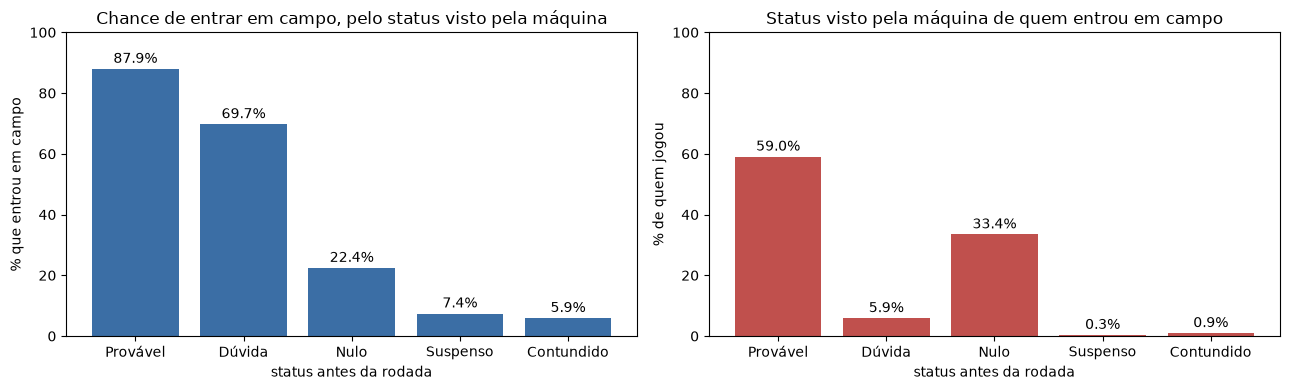

,% que jogou,% de quem jogou
status_pre,,
Provável,87.9,59.0
Dúvida,69.7,5.9
Nulo,22.4,33.4
Suspenso,7.4,0.3
Contundido,5.9,0.9


In [7]:
#Relação entre o status de antes da rodada (o que a máquina vê) e quem entrou em campo
#Usa as rodadas 2 em diante, sem o status emprestado da rodada 1
st = base[(base["rodada"] >= 2) & base["adversario_id"].notna() & ~base["status_emprestado"].astype(bool)]
ordem = ["Provável", "Dúvida", "Nulo", "Suspenso", "Contundido"]

#Chance de jogar em cada status e status de quem jogou
taxa = 100 * st.groupby("status_pre")["em_campo"].mean().reindex(ordem)
quem = 100 * st[st["em_campo"]]["status_pre"].value_counts(normalize=True).reindex(ordem)

#Gráfico: à esquerda, a chance de jogar em cada status; à direita, o status que a máquina via para quem jogou
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(ordem, taxa.values, color="#3b6ea5")
ax[0].set(title="Chance de entrar em campo, pelo status visto pela máquina", xlabel="status antes da rodada",
          ylabel="% que entrou em campo", ylim=(0, 100))
ax[1].bar(ordem, quem.values, color="#c0504d")
ax[1].set(title="Status visto pela máquina de quem entrou em campo", xlabel="status antes da rodada",
          ylabel="% de quem jogou", ylim=(0, 100))
#Valor em cima de cada barra
for a, valores in [(ax[0], taxa.values), (ax[1], quem.values)]:
    for x, v in enumerate(valores):
        a.text(x, v + 2, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()


pd.DataFrame({"% que jogou": taxa, "% de quem jogou": quem}).round(1)

O gráfico mostra o problema de forma direta. Dos atletas que a máquina vê como prováveis, 12,1% não jogam, e entre os que estão em dúvida, 30% não jogam. Parte desses erros vem de informações que mudaram durante a semana e que um cartoleiro atento teria (seção 3.5). Além disso, um terço dos atletas que entraram em campo (33,4%) aparecia como nulo no status visto pela máquina. Muitos são reservas que entraram no segundo tempo, mas outros são titulares que voltaram de lesão ou de suspensão durante a semana.

Como apenas prováveis e dúvidas têm chance alta de jogar, eles são os candidatos à escalação, e o alvo zero para quem não jogou coloca o risco de ausência dentro da previsão. Os reservas cobrem parte das ausências que sobram.

## 5.4 Regra de variação de preço

In [8]:
#Regressão da variação de preço em função dos pontos e do preço, separada por temporada
coef = {}
for ano, g in em.groupby("ano"):
    Xp = np.column_stack([g["pontos"], g["preco_pre"], np.ones(len(g))])
    coef[ano] = np.linalg.lstsq(Xp, g["variacao"].values, rcond=None)[0]
coef = pd.DataFrame(coef, index=["pontos", "preço", "constante"]).T


coef.round(3)

,pontos,preço,constante
2018,0.219,-0.089,-0.046
2019,0.221,-0.085,-0.055
2020,0.215,-0.089,-0.005
2021,0.222,-0.083,-0.058
2022,0.212,-0.089,-0.086
2023,0.207,-0.097,-0.049
2024,0.192,-0.127,0.124
2025,0.194,-0.123,0.143
2026,0.194,-0.122,0.116


A variação de preço depende dos pontos feitos e do próprio preço, já que atletas caros sobem menos. O peso do preço ficou perto de -0,09 até 2023 e passou para cerca de -0,12 a partir de 2024, o que indica que o Cartola mudou a regra. Por isso a regra de preço usada como atributo (o mínimo de pontos para o atleta não perder valor) é ajustada apenas nos anos de treino, e essa mudança fica registrada como limitação.

# 6. Preparação

## 6.1 Tratamento dos dados
O tratamento descrito na seção 4.3 cobre os itens de preparação dos dados. Os valores ausentes foram tratados mantendo como desconhecidos os scouts de colunas que não existem em um arquivo, inferindo quem entrou em campo até 2022 e emprestando o status da rodada 1; nas médias, valores ausentes são ignorados e os pesos são redistribuídos. A duplicidade da rodada 1 de 2021 foi resolvida mantendo o resultado. As inconsistências de formato foram unificadas e os acumulados que diminuem foram corrigidos. Os outliers, como os picos de acumulado, foram anulados, e as rodadas com volume anormal de scouts foram marcadas como não confiáveis. As variáveis categóricas (posição, status, era dos scouts e papel tático) são tratadas como categorias pelo próprio LightGBM, e os pontos foram padronizados por temporada; o modelo de árvores não exige normalizar as demais variáveis.

## 6.2 Criação de atributos
Todos os atributos de uma rodada usam apenas informações de rodadas anteriores. Eles cobrem o histórico do atleta (número de jogos, última pontuação, variação média de preço e desempenho na temporada anterior), médias ponderadas de pontos e scouts, a disponibilidade (fração de jogos disputados e de jogos como titular), o papel tático, a força do clube e do adversário, os pontos que o adversário costuma ceder, a chance de cobrar pênalti, a marcação de clubes promovidos e o preço.

A função para_antes transforma uma estatística que inclui o jogo atual em outra que usa apenas jogos anteriores, e é o principal cuidado contra vazamento nos atributos. As médias ponderadas dão peso 1 aos cinco jogos mais recentes, 0,6 aos cinco anteriores, 0,36 aos próximos e assim por diante, até 30 jogos, atravessando temporadas.

In [9]:
#Histórico básico do atleta e médias ponderadas por blocos de 5 jogos

#Scouts usados nos atributos e chave de cada atleta na temporada
SCOUTS = ["G", "A", "FT", "FD", "FF", "FS", "I", "PP", "DS_h", "SG", "DP", "GS", "FC", "CA", "CV", "GC"]
CH = ["ano", "atleta_id"]


#Transforma uma estatística que inclui o jogo atual em uma que só usa jogos anteriores:
#pega o valor da linha anterior do atleta e repete nas rodadas em que ele não jogou.
def para_antes(df, cols):
    df[cols] = df.groupby(CH)[cols].shift()
    df[cols] = df.groupby(CH)[cols].ffill()
    return df


#Histórico simples de cada atleta, só com rodadas anteriores: nº de jogos, variação média de preço
#nas 3 últimas aparições, última pontuação, média dos 5 últimos jogos e média padronizada e nº de
#jogos da temporada anterior.
def historico_atleta(base):
    base = base.sort_values(["ano", "atleta_id", "rodada"]).copy()
    g = base.groupby(CH)
    base["n_jogos_antes"] = g["em_campo"].transform(lambda s: s.astype(float).shift().fillna(0).cumsum())
    base["var_media_3"] = g["variacao"].transform(lambda s: s.shift().rolling(3, min_periods=1).mean())

    jogos = base[base["em_campo"]]
    depois = pd.DataFrame(index=jogos.index)
    depois["ultima"] = jogos["pontos"]
    depois["media_5"] = jogos.groupby(CH)["pontos"].transform(lambda s: s.rolling(5, min_periods=1).mean())
    base = base.join(depois)
    base = para_antes(base, ["ultima", "media_5"])

    ano_ant = jogos.groupby(CH).agg(media_z_temp_ant=("pontos_z", "mean"), jogos_temp_ant=("pontos", "size"))
    ano_ant = ano_ant.reset_index()
    ano_ant["ano"] += 1
    base = base.merge(ano_ant, on=CH, how="left")
    base["jogos_temp_ant"] = base["jogos_temp_ant"].fillna(0)
    return base


#Média de pontos de cada posição na temporada até a rodada anterior.
def media_posicao(base):
    jogos = base[base["em_campo"]]
    mp = jogos.groupby(["ano", "posicao", "rodada"])["pontos"].agg(["sum", "size"]).reset_index()
    mp = mp.sort_values(["ano", "posicao", "rodada"])
    g = mp.groupby(["ano", "posicao"])
    soma = g["sum"].transform(lambda s: s.shift().cumsum())
    qtd = g["size"].transform(lambda s: s.shift().cumsum())
    mp["media_posicao"] = soma / qtd
    return base.merge(mp[["ano", "posicao", "rodada", "media_posicao"]], on=["ano", "posicao", "rodada"], how="left")


#Pesos das médias ponderadas
BLOCO = 5
QUEDA = 0.6
MAX_JOGOS = 30


#Peso de cada jogo anterior: os 5 mais recentes pesam 1, os 5 seguintes 0,6,
#os próximos 0,36, e assim por diante até 30 jogos.
def pesos():
    return np.array([QUEDA ** ((k - 1) // BLOCO) for k in range(1, MAX_JOGOS + 1)])


#Média ponderada dos jogos anteriores de cada grupo (ex.: de cada atleta).
#Para k = 1..30 pega o valor de k jogos atrás, multiplica pelo peso e soma; no fim divide pela
#soma dos pesos dos valores que existem. Em `desvio` calcula também o desvio ponderado.
#Com com_atual=True a própria linha conta como o jogo mais recente.
def media_ponderada(df, chave, cols, ordem, desvio=None, com_atual=False):
    w = pesos()
    d = df.sort_values(chave + ordem)
    grupo = d.groupby(chave)[cols]
    soma = pd.DataFrame(0.0, index=d.index, columns=cols)
    soma2 = soma.copy()
    peso = soma.copy()
    ini = 0 if com_atual else 1
    for k in range(ini, MAX_JOGOS + ini):
        if k == 0:
            val = d[cols]
        else:
            val = grupo.shift(k)
        wk = w[k - ini]
        soma += val.fillna(0) * wk
        soma2 += (val.fillna(0) ** 2) * wk
        peso += val.notna() * wk

    media = soma / peso.replace(0, np.nan)
    n = d.groupby(chave).cumcount() + ini
    media[n < 1] = np.nan
    saida = media.add_suffix("_pond")
    if desvio:
        var = soma2[desvio] / peso[desvio].replace(0, np.nan) - media[desvio] ** 2
        saida = saida.join(np.sqrt(var.clip(lower=0)).add_suffix("_dp_pond"))
    return saida.reindex(df.index)


#Igual à média ponderada, mas devolve só a soma ponderada dos jogos anteriores.
def soma_ponderada(df, chave, cols, ordem):
    w = pesos()
    d = df.sort_values(chave + ordem)
    grupo = d.groupby(chave)[cols]
    soma = pd.DataFrame(0.0, index=d.index, columns=cols)
    for k in range(1, MAX_JOGOS + 1):
        soma += grupo.shift(k).fillna(0) * w[k - 1]
    return soma.reindex(df.index)

O Cartola não informa quem cobrou cada pênalti, apenas quem fez gol, quem perdeu pênalti e quantos pênaltis o time sofreu. O modelo Cobrador estima isso. Cada atleta tem uma força, e a chance de cobrar é dividida entre os jogadores em campo por softmax; assim, se o cobrador habitual não joga, a chance dos outros aumenta. Quando o time converte um pênalti e mais de um jogador fez gol, o crédito é dividido entre eles na proporção da chance de cada um. As forças são atualizadas por gradiente, revendo todo o histórico a cada rodada, e partem de um valor inicial por posição, com atacantes e meias mais prováveis.

In [10]:
#Modelo do cobrador de pênalti

#Força inicial de cada posição
PRIOR = {"GOL": -4.0, "ZAG": -1.5, "LAT": -1.0, "MEI": 0.0, "ATA": 0.5}


#Modelo de cobrador de pênalti. Cada atleta tem uma força; a chance de cobrar é dividida
#entre os jogadores em campo por softmax.
class Cobrador:

    #eta é o tamanho do passo e lam a força que puxa cada atleta de volta para o prior da posição.
    def __init__(self, eta=0.5, lam=0.05):
        self.eta = eta
        self.lam = lam
        self.forca = {}
        self.pos = {}

    #Força do atleta; na primeira vez começa no prior da posição.
    def forca_de(self, jog, pos):
        if jog not in self.forca:
            self.forca[jog] = PRIOR.get(pos, 0.0)
            self.pos[jog] = pos
        return self.forca[jog]

    #Chance de cada jogador em campo cobrar: exp(força) / soma dos exp(força) dos que estão em campo.
    def chances(self, campo):
        f = {j: self.forca_de(j, p) for j, p in campo.items()}
        maior = max(f.values())
        ex = {j: math.exp(v - maior) for j, v in f.items()}
        tot = sum(ex.values())
        return {j: v / tot for j, v in ex.items()}

    #Divide um pênalti convertido entre os autores de gol, na proporção (chance de cobrar x gols).
    def credito(self, ev):
        ch = self.chances(ev["campo"])
        w = {j: ch[j] * ev["gols"][j] for j in ev["gols"] if j in ch}
        tot = sum(w.values())
        if tot == 0:
            return {}
        return {j: v / tot for j, v in w.items()}

    #Atualiza as forças com um evento: cada atleta em campo recebe eta·(crédito - chance).
    #Quem marcou e era provável cobrador sobe; quem não marcou desce. Pênalti perdido mostra
    #o cobrador com certeza.
    def passo(self, ev):
        ch = self.chances(ev["campo"])
        grad = defaultdict(float)
        for _ in range(ev["convertidos"]):
            cr = self.credito(ev)
            for j in ch:
                grad[j] += cr.get(j, 0.0) - ch[j]
        for quem, n in ev["perdidos"].items():
            if quem in ch:
                for j in ch:
                    alvo = 1.0 if j == quem else 0.0
                    grad[j] += n * (alvo - ch[j])
        for j, g in grad.items():
            self.forca[j] += self.eta * g

    #Repassa todo o histórico (os casos ambíguos antigos são reavaliados com as forças atuais)
    #e puxa as forças de volta para o prior da posição.
    def ajustar(self, hist, epocas=5):
        for _ in range(epocas):
            for ev in hist:
                self.passo(ev)
            for j in self.forca:
                prior = PRIOR.get(self.pos[j], 0.0)
                self.forca[j] -= self.eta * self.lam * (self.forca[j] - prior)

A titularidade é inferida pelas ações na rodada: em cada clube, o goleiro e os 10 jogadores de linha com mais ações são considerados titulares. O papel tático combina um índice ofensivo com grupos formados por K-means a partir do perfil de scouts da temporada; o número de grupos de cada posição (2, 3 ou 4) é escolhido pela silhueta, e o ajuste usa apenas os anos de treino.

O Elo mede a força de cada clube e é atualizado pelos placares, com peso maior para goleadas e vantagem de 60 pontos para o mandante. O valor usado para prever uma rodada é registrado antes dos jogos dela. Na virada de temporada o Elo volta 25% em direção a 1500, e os clubes que subiram da Série B começam no nível dos quatro piores do ano anterior. Na função penalti, a chance de cada atleta cobrar é calculada antes de os pênaltis da rodada entrarem no histórico do modelo.

In [11]:
#Titularidade, papel tático, Elo dos clubes e atributos de pênalti

#Anos de treino, scouts ofensivos e defensivos e ordem cronológica
ANOS_TREINO = list(range(2018, 2025))
OF = ["FF", "FD", "FT", "G", "A", "FS"]
DE = ["DS_h", "FC"]
ORDEM = ["ano", "rodada"]


#Descobre quem foi titular: em cada clube e rodada, o goleiro com mais ações e os 10 jogadores
#de linha com mais ações. Quem não jogou fica com 0.
def titularidade(vdg):
    jog = vdg[vdg["em_campo"] & vdg["scouts_confiaveis"]].copy()
    acoes = [s for s in SCOUTS if s not in ("SG", "GS")] + ["DE"]
    jog["acoes"] = jog[acoes].sum(axis=1)
    goleiro = jog["posicao"] == "GOL"
    jog["rank"] = jog.groupby(["ano", "rodada", "clube_id", goleiro])["acoes"].rank(ascending=False, method="first")
    jog["titular_inf"] = np.where(goleiro, jog["rank"] <= 1, jog["rank"] <= 10).astype(float)

    vdg = vdg.merge(jog[["ano", "rodada", "atleta_id", "titular_inf"]], on=["ano", "rodada", "atleta_id"], how="left")
    vdg.loc[~vdg["em_campo"], "titular_inf"] = 0.0
    return vdg.sort_values(["ano", "atleta_id", "rodada"])


#Estilo de jogo de cada atleta. Soma scouts ofensivos e defensivos dos 5 jogos anteriores e
#calcula o índice ofensivo. Depois separa os atletas de cada posição em grupos com K-means, pelo
#perfil de scouts da temporada (2, 3 ou 4 grupos, escolhidos pela silhueta, só com anos de treino).
def papel_tatico(vdg):
    vdg = vdg.sort_values(["ano", "atleta_id", "rodada"]).copy()
    valeu = vdg["em_campo"] & vdg["scouts_confiaveis"]
    for nome, cols in [("of", OF), ("de", DE)]:
        vdg["_tmp"] = vdg[cols].sum(axis=1).where(valeu)
        vdg[f"{nome}_m5"] = vdg.groupby(CH)["_tmp"].transform(lambda s: s.shift().rolling(5, min_periods=1).sum())
    vdg = vdg.drop(columns="_tmp")
    vdg["ind_ofensivo"] = vdg["of_m5"] / (vdg["of_m5"] + vdg["de_m5"]).replace(0, np.nan)

    cols = ["G", "A", "FT", "FD", "FF", "FS", "I", "DS_h", "FC", "CA"]
    acum = vdg[cols].fillna(0).mul(valeu.astype(float), axis=0)
    acum = acum.groupby([vdg["ano"], vdg["atleta_id"]]).cumsum()
    acum = acum.groupby([vdg["ano"], vdg["atleta_id"]]).shift()
    perfil = acum.div(acum.sum(axis=1).replace(0, np.nan), axis=0)
    ok = perfil.notna().all(axis=1) & (vdg["n_jogos_antes"] >= 3)

    vdg["cluster_papel"] = "sem_perfil"
    for pos in ["LAT", "ZAG", "MEI", "ATA"]:
        da_pos = (vdg["posicao"] == pos) & ok
        treino = da_pos & vdg["ano"].isin(ANOS_TREINO)
        linhas = vdg[treino].groupby(CH)["rodada"].idxmax()
        X = perfil.loc[linhas].values
        melhor = None
        for k in (2, 3, 4):
            km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
            nota = silhouette_score(X, km.labels_, sample_size=min(3000, len(X)), random_state=SEED)
            if melhor is None or nota > melhor[0]:
                melhor = (nota, k, km)
        nota, k, km = melhor
        grupos = km.predict(perfil.loc[da_pos].values)
        vdg.loc[da_pos, "cluster_papel"] = [f"{pos}_{g}" for g in grupos]
        print(f"  {pos}: {k} grupos (silhueta {nota:.3f})")
    return vdg


#Força (Elo) de cada clube rodada a rodada. Primeiro guarda o Elo antes dos jogos da rodada,
#depois atualiza com os placares: quem vence ganha pontos de acordo com a surpresa do resultado,
#com bônus para o mandante e peso maior para goleadas. Na virada de temporada o Elo volta um pouco
#para 1500, e quem subiu da Série B começa no nível dos 4 piores do ano anterior.
def elo_clubes(vdg, K=20.0, mando=60.0, volta=0.75):
    jog = vdg[vdg["em_campo"] & vdg["scouts_confiaveis"] & vdg["adversario_id"].notna()]
    t = jog.groupby(["ano", "rodada", "clube_id"]).agg(G=("G", "sum"), GC=("GC", "sum"),
                                                       adv=("adversario_id", "first"), mando=("mando", "first"))
    t = t.reset_index()
    contra = t[["ano", "rodada", "clube_id", "GC"]].rename(columns={"clube_id": "adv", "GC": "GC_adv"})
    t = t.merge(contra, on=["ano", "rodada", "adv"])
    t["gols"] = t["G"] + t["GC_adv"]
    gols = t.set_index(["ano", "rodada", "clube_id"])["gols"]

    elo = defaultdict(lambda: 1450.0)
    linhas = []
    clubes_ano = vdg.groupby("ano")["clube_id"].apply(set).to_dict()
    for ano in sorted(vdg["ano"].unique()):
        anteriores = clubes_ano.get(ano - 1, set())
        if anteriores:
            piores = sorted(elo[c] for c in anteriores)[:4]
        else:
            piores = [1450.0]
        nivel_subiu = float(np.mean(piores))
        for c in list(elo):
            elo[c] = 1500 + volta * (elo[c] - 1500)
        for c in clubes_ano[ano]:
            if anteriores and c not in anteriores:
                elo[c] = 1500 + volta * (nivel_subiu - 1500)

        casa = t[(t["ano"] == ano) & (t["mando"] == 1)]
        for rodada in sorted(vdg.loc[vdg["ano"] == ano, "rodada"].unique()):
            for c in vdg.loc[(vdg["ano"] == ano) & (vdg["rodada"] == rodada), "clube_id"].unique():
                linhas.append((ano, rodada, c, elo[c]))
            for _, jogo in casa[casa["rodada"] == rodada].iterrows():
                h, a = jogo["clube_id"], int(jogo["adv"])
                gh, ga = jogo["gols"], gols.get((ano, rodada, a), np.nan)
                if np.isnan(ga):
                    continue
                esperado = 1 / (1 + 10 ** (-(elo[h] + mando - elo[a]) / 400))
                if gh > ga:
                    res = 1.0
                elif gh == ga:
                    res = 0.5
                else:
                    res = 0.0
                peso = math.log(abs(gh - ga) + 1) + 1
                elo[h] += K * peso * (res - esperado)
                elo[a] -= K * peso * (res - esperado)
    return pd.DataFrame(linhas, columns=["ano", "rodada", "clube_id", "elo"])


#Atributos de pênalti: média de pênaltis a favor do time e cometidos pelo adversário nos
#10 jogos anteriores, e a chance de cada atleta ser o cobrador (modelo Cobrador). A chance é
#calculada antes da rodada; só depois os pênaltis dela entram no histórico do modelo.
def penalti(vdg):
    jog = vdg[vdg["em_campo"] & vdg["scouts_confiaveis"]]
    t = jog.groupby(["ano", "rodada", "clube_id"]).agg(PS=("PS", "sum"), PC=("PC", "sum"), PP=("PP", "sum"),
                                                       adv=("adversario_id", "first")).reset_index()
    contra = t[["ano", "rodada", "clube_id", "PC"]].rename(columns={"clube_id": "adv", "PC": "PC_adv"})
    t = t.merge(contra, on=["ano", "rodada", "adv"], how="left")
    t["batidos"] = np.maximum(t["PS"], t["PC_adv"].fillna(0))
    t = t.sort_values(["ano", "clube_id", "rodada"])
    g = t.groupby(["ano", "clube_id"])
    t["taxa_pen_time"] = g["batidos"].transform(lambda s: s.shift().rolling(10, min_periods=1).mean())
    t["taxa_pen_cometido"] = g["PC"].transform(lambda s: s.shift().rolling(10, min_periods=1).mean())

    times = {k: g for k, g in jog.groupby(["ano", "rodada", "clube_id"])}
    eventos = defaultdict(list)
    for r in t.itertuples():
        time = times.get((r.ano, r.rodada, r.clube_id))
        if time is None:
            continue
        perdidos = {a: int(p) for a, p in zip(time["atleta_id"], time["PP"]) if p > 0}
        convertidos = int(max(r.batidos - sum(perdidos.values()), 0))
        gols = {a: int(x) for a, x in zip(time["atleta_id"], time["G"]) if x > 0}
        if convertidos and not gols:
            convertidos = 0
        if convertidos or perdidos:
            eventos[(r.ano, r.rodada)].append({"campo": dict(zip(time["atleta_id"], time["posicao"])),
                                               "convertidos": convertidos, "gols": gols, "perdidos": perdidos})

    cand = vdg[vdg["status_pre"].isin(["Provável", "Dúvida"])]
    cand_rodada = defaultdict(list)
    for (a, r, c), time in cand.groupby(["ano", "rodada", "clube_id"]):
        cand_rodada[(a, r)].append(time)

    modelo = Cobrador()
    hist = []
    chance = {}
    for ano in sorted(vdg["ano"].unique()):
        for j in modelo.forca:
            prior = PRIOR.get(modelo.pos[j], 0.0)
            modelo.forca[j] = prior + 0.7 * (modelo.forca[j] - prior)
        for rodada in sorted(vdg.loc[vdg["ano"] == ano, "rodada"].unique()):
            for time in cand_rodada.get((ano, rodada), []):
                prov = time[time["status_pre"] == "Provável"]
                if len(prov):
                    campo = dict(zip(prov["atleta_id"], prov["posicao"]))
                else:
                    campo = dict(zip(time["atleta_id"], time["posicao"]))
                ch = modelo.chances(campo)
                for jid in time["atleta_id"]:
                    chance[(ano, rodada, jid)] = ch.get(jid, 0.0)
            hist += eventos.get((ano, rodada), [])
            hist = hist[-400:]
            modelo.ajustar(hist[-150:], epocas=2)

    vdg["p_cobrar_penalti"] = [chance.get(k, np.nan) for k in zip(vdg["ano"], vdg["rodada"], vdg["atleta_id"])]
    vdg = vdg.merge(t[["ano", "rodada", "clube_id", "taxa_pen_time"]], on=["ano", "rodada", "clube_id"], how="left")
    adv = t[["ano", "rodada", "clube_id", "taxa_pen_cometido"]]
    adv = adv.rename(columns={"clube_id": "adversario_id", "taxa_pen_cometido": "adv_taxa_pen_cometido"})
    vdg = vdg.merge(adv, on=["ano", "rodada", "adversario_id"], how="left")
    vdg["pen_esperado"] = vdg["p_cobrar_penalti"] * (vdg["taxa_pen_time"].fillna(0) + vdg["adv_taxa_pen_cometido"].fillna(0)) / 2
    return vdg

A regra de preço é ajustada apenas no treino, e dela sai o mínimo de pontos para o atleta não perder valor. Os pontos cedidos pelo adversário são puxados para a média da liga com peso de 10 atletas, para que poucos jogos não gerem valores extremos. Até a rodada 8, as estatísticas antigas dos clubes promovidos são apagadas, porque podem ser de anos distantes na Série A.

A função media_baseline calcula a previsão do baseline: a média do atleta no Cartola antes da rodada, que é o número que o aplicativo mostra. Na primeira rodada, quando ainda não há média, usa a média do atleta na temporada anterior; sem histórico, a média da posição na temporada anterior.

A função construir junta todos os grupos e define o alvo, que são os pontos se o atleta jogou e zero se não jogou, e os candidatos, que são os atletas prováveis ou em dúvida (incluindo o status emprestado da rodada 1) cujo clube tem jogo na rodada.

In [12]:
#Regra de preço, médias ponderadas de clubes, promovidos, baseline e montagem da tabela


#Ajusta no treino a regra de preço (variação = a·pontos + b·preço + c·média5 + d) e calcula
#quantos pontos cada atleta precisa fazer para não perder valor.
def regra_preco(vdg):
    e = vdg[vdg["em_campo"] & vdg["ano"].isin(ANOS_TREINO) & vdg["media_5"].notna()]
    X = np.column_stack([e["pontos"], e["preco_pre"], e["media_5"], np.ones(len(e))])
    coef = np.linalg.lstsq(X, e["variacao"].values, rcond=None)[0]
    a, bp, c, d = coef
    print(f"  variação = {a:.3f}·pontos {bp:+.3f}·preço {c:+.3f}·média5 {d:+.3f}")
    media = vdg["media_5"].fillna(vdg["media_posicao"])
    vdg["minimo_valorizar"] = -(bp * vdg["preco_pre"] + c * media + d) / a
    return vdg


#Médias ponderadas por blocos de 5 jogos, atravessando temporadas: pontos e scouts do atleta,
#quanto ele joga e é titular, desempenho do clube e do adversário, e pontos cedidos pelo
#adversário (puxados para a média da liga quando há poucos jogos).
def ponderados(vdg):
    vdg = vdg.sort_values(["atleta_id"] + ORDEM).copy()

    jog = vdg[vdg["em_campo"]]
    cols = ["pontos", "pontos_z"] + SCOUTS
    atl = media_ponderada(jog, ["atleta_id"], cols, ORDEM, desvio=["pontos"], com_atual=True)
    novas = list(atl.columns)
    vdg = vdg.join(atl)
    vdg[novas] = vdg.groupby("atleta_id")[novas].shift()
    vdg[novas] = vdg.groupby("atleta_id")[novas].ffill()

    vdg["_em"] = vdg["em_campo"].astype(float)
    disp = media_ponderada(vdg, ["atleta_id"], ["_em", "titular_inf"], ORDEM)
    vdg["em_campo_pond"] = disp["_em_pond"]
    vdg["titular_pond"] = disp["titular_inf_pond"]
    vdg = vdg.drop(columns="_em")

    jog = vdg[vdg["em_campo"]]
    tc = jog.groupby(["ano", "rodada", "clube_id"]).agg(G=("G", "sum"), GC=("GC", "sum"), pts=("pontos", "sum"),
                                                        adv=("adversario_id", "first"),
                                                        conf=("scouts_confiaveis", "all")).reset_index()
    gs = jog[jog["posicao"] == "GOL"].groupby(["ano", "rodada", "clube_id"])["GS"].sum().rename("GS")
    tc = tc.merge(gs.reset_index(), on=["ano", "rodada", "clube_id"], how="left")
    contra = tc[["ano", "rodada", "clube_id", "GC"]].rename(columns={"clube_id": "adv", "GC": "GC_adv"})
    tc = tc.merge(contra, on=["ano", "rodada", "adv"], how="left")
    tc["gf"] = tc["G"] + tc["GC_adv"]
    tc["ga"] = tc["GS"]
    tc["sg"] = (tc["ga"] == 0).astype(float).where(tc["ga"].notna())
    tc.loc[~tc["conf"], ["gf", "ga", "sg"]] = np.nan
    tc = tc.join(media_ponderada(tc, ["clube_id"], ["gf", "ga", "sg", "pts"], ORDEM))
    clu = tc[["ano", "rodada", "clube_id", "gf_pond", "ga_pond", "sg_pond", "pts_pond"]]
    vdg = vdg.merge(clu, on=["ano", "rodada", "clube_id"], how="left")
    clu_adv = clu.rename(columns={"clube_id": "adversario_id", "gf_pond": "adv_gf_pond", "ga_pond": "adv_ga_pond",
                                  "sg_pond": "adv_sg_pond", "pts_pond": "adv_pts_pond"})
    vdg = vdg.merge(clu_adv, on=["ano", "rodada", "adversario_id"], how="left")

    jog = vdg[vdg["em_campo"] & vdg["adversario_id"].notna()]
    treino = jog[jog["ano"].isin(ANOS_TREINO)]
    media_pos = treino.groupby("posicao")["pontos"].mean()
    media_geral = treino["pontos"].mean()
    K = 10
    pos = jog.groupby(["ano", "rodada", "adversario_id", "posicao"])["pontos"].agg(soma="sum", n="size").reset_index()
    s = soma_ponderada(pos, ["adversario_id", "posicao"], ["soma", "n"], ORDEM)
    pos["cedido_pos_pond"] = (s["soma"] + K * pos["posicao"].map(media_pos)) / (s["n"] + K)
    ger = jog.groupby(["ano", "rodada", "adversario_id"])["pontos"].agg(soma="sum", n="size").reset_index()
    s = soma_ponderada(ger, ["adversario_id"], ["soma", "n"], ORDEM)
    ger["cedido_geral_pond"] = (s["soma"] + K * media_geral) / (s["n"] + K)
    vdg = vdg.merge(pos[["ano", "rodada", "adversario_id", "posicao", "cedido_pos_pond"]],
                on=["ano", "rodada", "adversario_id", "posicao"], how="left")
    vdg = vdg.merge(ger[["ano", "rodada", "adversario_id", "cedido_geral_pond"]], on=["ano", "rodada", "adversario_id"], how="left")
    return vdg


#Marca os clubes que subiram da Série B. Até a rodada 8 apaga as estatísticas antigas desses
#clubes, para o modelo ver só a marca de promovido e o Elo inicial fraco.
def promovidos(vdg, ate_rodada=8):
    clubes_ano = vdg.groupby("ano")["clube_id"].apply(set).to_dict()
    subiram = set()
    for a in clubes_ano:
        if (a - 1) in clubes_ano:
            for c in clubes_ano[a]:
                if c not in clubes_ano[a - 1]:
                    subiram.add((a, c))

    vdg["promovido"] = [float((a, c) in subiram) if (a - 1) in clubes_ano else np.nan
                      for a, c in zip(vdg["ano"], vdg["clube_id"])]
    vdg["adv_promovido"] = [float((a, c) in subiram) if (a - 1) in clubes_ano and not pd.isna(c) else np.nan
                          for a, c in zip(vdg["ano"], vdg["adversario_id"])]
    inicio = vdg["rodada"] <= ate_rodada
    vdg.loc[inicio & (vdg["promovido"] == 1), ["gf_pond", "ga_pond", "sg_pond", "pts_pond"]] = np.nan
    vdg.loc[inicio & (vdg["adv_promovido"] == 1),
          ["adv_gf_pond", "adv_ga_pond", "adv_sg_pond", "adv_pts_pond", "cedido_pos_pond", "cedido_geral_pond"]] = np.nan
    print(f"  clubes promovidos: {len(subiram)}")
    return vdg


#Previsão do baseline: a média do atleta no Cartola antes da rodada. Na 1ª rodada (sem média)
#usa a média dele na temporada anterior; sem histórico, a média da posição na temporada anterior.
def media_baseline(vdg):
    jog = vdg[vdg["em_campo"]]
    atl = jog.groupby(CH)["pontos"].mean().rename("media_ano_ant").reset_index()
    atl["ano"] += 1
    pos = jog.groupby(["ano", "posicao"])["pontos"].mean().rename("media_pos_ant").reset_index()
    pos["ano"] += 1
    vdg = vdg.merge(atl, on=CH, how="left").merge(pos, on=["ano", "posicao"], how="left")
    vdg["prev_media"] = vdg["media_cartola_pre"].fillna(vdg["media_ano_ant"]).fillna(vdg["media_pos_ant"]).fillna(0)
    return vdg


#Monta a tabela de atributos na ordem: histórico, média da posição, titularidade, papel tático,
#Elo, pênalti, médias ponderadas, promovidos, regra de preço e baseline. Define o alvo (pontos se
#jogou, 0 se não jogou) e os candidatos (Provável ou Dúvida, com jogo na rodada).
def construir():
    base = pd.read_csv(os.path.join(PROC, "base_2018_2026.csv.gz"), low_memory=False)
    print("histórico do atleta…")
    vdg = historico_atleta(base)
    vdg = media_posicao(vdg)
    print("titularidade…")
    vdg = titularidade(vdg)
    print("papel tático…")
    vdg = papel_tatico(vdg)
    print("Elo…")
    elo = elo_clubes(vdg)
    vdg = vdg.merge(elo, on=["ano", "rodada", "clube_id"], how="left")
    elo_adv = elo.rename(columns={"clube_id": "adversario_id", "elo": "adv_elo"})
    vdg = vdg.merge(elo_adv, on=["ano", "rodada", "adversario_id"], how="left")
    vdg["elo_dif"] = vdg["elo"] - vdg["adv_elo"] + 60 * (2 * vdg["mando"] - 1)
    print("pênalti…")
    vdg = penalti(vdg)
    print("médias ponderadas…")
    vdg = ponderados(vdg)
    print("promovidos…")
    vdg = promovidos(vdg)
    print("regra de preço…")
    vdg = regra_preco(vdg)
    vdg = media_baseline(vdg)

    vdg["pontos_esc"] = np.where(vdg["em_campo"], vdg["pontos"], 0.0)
    primeira = vdg.groupby("ano")["rodada"].transform("min")
    sem_status = (vdg["status_pre"] == "Desconhecido") & (vdg["rodada"] == primeira)
    vdg["candidato"] = (vdg["status_pre"].isin(["Provável", "Dúvida"]) | sem_status) & vdg["adversario_id"].notna()
    return vdg

In [13]:
#Montagem da tabela de atributos
inicio = time.time()
vdg = construir()

#Candidatos à escalação
c_todos = vdg[vdg["candidato"]]

print(f"\nconcluído em {time.time() - inicio:.0f} s")
print("TABELA DE ATRIBUTOS")
print(f"linhas: {len(vdg):,} | candidatos: {len(c_todos):,} | candidatos que entraram em campo: {100 * c_todos['em_campo'].mean():.1f}%")

histórico do atleta…


titularidade…
papel tático…


  LAT: 3 grupos (silhueta 0.258)
  ZAG: 2 grupos (silhueta 0.253)


  MEI: 2 grupos (silhueta 0.279)
  ATA: 2 grupos (silhueta 0.194)
Elo…


pênalti…


médias ponderadas…


promovidos…


  clubes promovidos: 32
regra de preço…
  variação = 0.199·pontos -0.045·preço -0.093·média5 -0.002



concluído em 37 s
TABELA DE ATRIBUTOS
linhas: 255,811 | candidatos: 70,632 | candidatos que entraram em campo: 85.8%


# 7. Protocolo experimental
Como os dados têm ordem no tempo, a divisão é temporal; uma divisão aleatória misturaria rodadas futuras no treino e daria resultados otimistas. O treino usa as temporadas de 2018 a 2024, a validação usa as rodadas 1 a 19 de 2025 e serve para escolher os hiperparâmetros, o teste usa as rodadas 20 a 38 de 2025, e a temporada de 2026 (rodadas 1 a 35) fica como holdout, sem ser usada em nenhuma escolha.

As previsões usadas na simulação seguem o esquema walk-forward: cada período é previsto por um modelo treinado apenas com dados anteriores a ele. A temporada de 2024 é prevista por um modelo treinado com 2018 a 2023; as rodadas 1 a 19 de 2025, por um modelo treinado com 2018 a 2024; as rodadas 20 a 38 de 2025, por um modelo treinado até a rodada 19 de 2025; e 2026, por um modelo treinado com 2018 a 2025.

O vazamento é evitado em três níveis. Nos dados, são usados o preço, o status e a média de antes da rodada (seção 4.3). Nos atributos, toda estatística usa apenas jogos anteriores, o Elo e a chance de cobrar pênalti são registrados antes da rodada, e o K-means e a regra de preço são ajustados só com os anos de treino. No treino, a divisão é temporal e os hiperparâmetros são escolhidos apenas na validação. A única exceção é o status emprestado da rodada 1, discutido na seção 3.5.

As métricas de previsão são calculadas rodada a rodada e depois tiradas as médias. O Spearman mede se o modelo ordena bem os atletas. O Top-11 é a média dos pontos reais dos 11 atletas com maior previsão, a métrica mais próxima da decisão de escalar. O MAE é o erro absoluto médio. Essas métricas consideram as rodadas a partir da sexta, quando já há histórico na temporada, e as rodadas iniciais são analisadas à parte na seção 9.4. Na simulação, as medidas são os pontos por rodada, o patrimônio final e os titulares que não jogaram.

In [14]:
#Separação dos conjuntos de treino, validação, teste e holdout (só os candidatos)
c = vdg[vdg["candidato"]].copy()

#Variáveis categóricas como texto
for col in ["posicao", "status_pre", "era_scouts", "cluster_papel"]:
    c[col] = c[col].astype(str)

tr = c[c["ano"] <= 2024]
va = c[(c["ano"] == 2025) & (c["rodada"] <= 19)]
te = c[(c["ano"] == 2025) & (c["rodada"] >= 20)]
ho = c[c["ano"] == 2026]

print("DIVISÃO DOS DADOS")
print("Treino (2018–2024):", len(tr))
print("Validação (2025, rodadas 1–19):", len(va))
print("Teste (2025, rodadas 20–38):", len(te))
print("Holdout (2026):", len(ho))

DIVISÃO DOS DADOS
Treino (2018–2024): 55436
Validação (2025, rodadas 1–19): 3974
Teste (2025, rodadas 20–38): 3927
Holdout (2026): 7295


# 8. Modelagem

## 8.1 Baseline
O baseline imita um cartoleiro comum: escalar os atletas de maior média no Cartola. Ele usa os mesmos candidatos e o mesmo otimizador do modelo, com as mesmas regras, orçamento, capitão e reservas. A única diferença é a previsão usada, então a comparação mede exatamente o que o aprendizado de máquina acrescenta.

## 8.2 LightGBM
O modelo principal é um LightGBM de regressão. Os dados são tabulares, com relações não lineares (o efeito do preço depende da posição, o do adversário depende do mando), muitas variáveis com valores ausentes e variáveis categóricas, e os modelos de gradient boosting com árvores tratam tudo isso sem pré-processamento extra. Na primeira versão do projeto, com menos atributos, também foram testadas a média do atleta e uma regressão Ridge: o LightGBM teve o melhor Spearman, e o Ridge teve Top-11 parecido.

O alvo são os pontos na rodada, com zero para quem não jogou, e o modelo usa 53 atributos numéricos e 4 categóricos. Os hiperparâmetros foram escolhidos por busca em grade, combinando o número de folhas (15, 31 ou 63), o mínimo de exemplos por folha (20, 50 ou 100) e o peso dos anos (todos iguais, ou anos antigos valendo 0,85 por ano de distância). A taxa de aprendizado é de 0,03, cada árvore usa 80% das linhas e das colunas, e o treino para quando 100 árvores seguidas não melhoram a validação. A combinação escolhida é a de maior Top-11 na validação, com o Spearman como desempate.

In [15]:
#Atributos usados pelo modelo e funções de avaliação e treino

RODADA_MIN = 6
NUM = (["preco_pre", "var_media_3", "minimo_valorizar",
        "pontos_pond", "pontos_dp_pond", "pontos_z_pond", "ultima", "n_jogos_antes", "media_cartola_pre",
        "media_z_temp_ant", "jogos_temp_ant",
        "em_campo_pond", "titular_pond",
        "mando", "rodada",
        "gf_pond", "ga_pond", "sg_pond", "pts_pond", "adv_gf_pond", "adv_ga_pond", "adv_sg_pond", "adv_pts_pond",
        "elo", "adv_elo", "elo_dif", "promovido", "adv_promovido",
        "cedido_pos_pond", "cedido_geral_pond",
        "of_m5", "de_m5", "ind_ofensivo",
        "p_cobrar_penalti", "taxa_pen_time", "adv_taxa_pen_cometido", "pen_esperado"]
       + [f"{s}_pond" for s in SCOUTS])
CAT = ["posicao", "status_pre", "era_scouts", "cluster_papel"]
COLS = NUM + CAT
GRUPOS = {
    "titularidade": ["titular_pond"],
    "papel tático": ["of_m5", "de_m5", "ind_ofensivo", "cluster_papel"],
    "Elo": ["elo", "adv_elo", "elo_dif"],
    "pontos cedidos": ["cedido_pos_pond", "cedido_geral_pond"],
    "pênalti": ["p_cobrar_penalti", "taxa_pen_time", "adv_taxa_pen_cometido", "pen_esperado"],
}


#Pega as colunas de atributos e marca as categóricas como category (o LightGBM usa direto).
def X(d, cols):
    x = d[cols].copy()
    for c in cols:
        if c in CAT:
            x[c] = x[c].astype("category")
    return x


#Avalia uma previsão rodada a rodada (a partir da rodada 6): Spearman entre previsto e real,
#Top-11 (pontos reais médios dos 11 com maior previsão) e erro absoluto médio.
def avaliar(d, col):
    d = d[d["rodada"] >= RODADA_MIN]
    sp, top = [], []
    for _, rod in d.groupby(["ano", "rodada"]):
        sp.append(rod[col].rank().corr(rod["pontos_esc"].rank()))
        top.append(rod.nlargest(11, col)["pontos_esc"].mean())
    erro = (d[col] - d["pontos_esc"]).abs().mean()
    return {"Spearman": pd.Series(sp).mean(), "Top-11": pd.Series(top).mean(), "MAE": erro}


#Treina o LightGBM. Com `queda`, anos antigos pesam menos (queda^anos de distância).
#Com dados de validação, para quando 100 árvores seguidas não melhoram.
def treinar(d, params, cols, queda, arvores, val=None):
    m = lgb.LGBMRegressor(**params, n_estimators=arvores)
    peso = None
    if queda:
        peso = queda ** (d["ano"].max() - d["ano"])
    extra = {}
    if val is not None:
        extra = dict(eval_set=[(X(val, cols), val["pontos_esc"])], callbacks=[lgb.early_stopping(100, verbose=False)])
    m.fit(X(d, cols), d["pontos_esc"], sample_weight=peso, **extra)
    return m

In [16]:
#Busca em grade dos hiperparâmetros, escolhendo pelo Top-11 na validação
inicio = time.time()
melhor, grade = None, []

for folhas in [15, 31, 63]:
    for minimo in [20, 50, 100]:
        for queda in [None, 0.85]:
            params = dict(objective="regression", learning_rate=0.03, num_leaves=folhas, min_child_samples=minimo,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)

            #Treina com parada antecipada na validação e avalia
            m = treinar(tr, params, COLS, queda, 3000, val=va)
            r = avaliar(va.assign(p=m.predict(X(va, COLS))), "p")
            grade.append({"folhas": folhas, "mínimo por folha": minimo, "queda": queda, "árvores": m.best_iteration_,
                          "Top-11": r["Top-11"], "Spearman": r["Spearman"]})

            #Guarda a melhor combinação
            nota = (r["Top-11"], r["Spearman"])
            if melhor is None or nota > melhor[0]:
                melhor = (nota, params, queda, m.best_iteration_)

_, params, queda, arvores = melhor
print(f"busca concluída em {time.time() - inicio:.0f} s")
print(f"escolhido: folhas={params['num_leaves']}, mínimo por folha={params['min_child_samples']}, queda={queda}, árvores={arvores}")
pd.DataFrame(grade).sort_values("Top-11", ascending=False).round(3).head(8)

busca concluída em 36 s
escolhido: folhas=31, mínimo por folha=100, queda=None, árvores=172


,folhas,mínimo por folha,queda,árvores,Top-11,Spearman
10,31,100,NaN,172,6.425,0.271
5,15,100,0.85,234,6.201,0.261
12,63,20,NaN,182,6.201,0.269
2,15,50,NaN,436,6.116,0.273
8,31,50,NaN,134,6.108,0.269
9,31,50,0.85,143,6.084,0.268
16,63,100,NaN,151,6.066,0.269
14,63,50,NaN,123,6.065,0.266


As diferenças entre as combinações são pequenas, de décimos de ponto no Top-11, o que indica que o modelo não depende de um ajuste fino. Nos modelos finais, o número de árvores é aumentado em 10%, porque eles são treinados com mais dados.

## 8.3 Otimizador de escalação
A escalação de cada rodada é resolvida como um problema de programação inteira, com a função milp do scipy. Cada atleta, o capitão, o técnico e a formação são variáveis que valem 0 ou 1. O objetivo é maximizar a soma dos pontos previstos dos titulares, mais o bônus do capitão (que vale 1,5 vez), mais o técnico, menos as penalidades por concentrar atletas do mesmo clube.

As restrições exigem uma formação oficial válida, um técnico, um capitão que esteja escalado e um custo total que não passe do patrimônio do momento. Para não depender de um único clube numa rodada ruim, até dois defensores do mesmo clube são livres, o terceiro custa 2 pontos e o quarto é proibido; entre meias e atacantes, até dois são livres, o terceiro custa 2 pontos, o quarto custa mais 5 e o quinto é proibido. Os pontos esperados do técnico são a média das cinco rodadas anteriores.

Depois dos titulares, é escolhido um reserva por posição: o de maior previsão entre os que custam no máximo o titular mais barato da posição. A partir de 2025, o reserva com maior vantagem prevista vira o Reserva de Luxo. A simulação percorre a temporada rodada a rodada: escala com o patrimônio atual, aplica os pontos e as variações de preço reais, atualiza o patrimônio e segue para a rodada seguinte. As premissas são que o capitão vale sempre 1,5 vez e perde o bônus se não jogar, que o preço do reserva não é descontado e que a variação do reserva só conta se ele entrar em campo.

In [17]:
#Regras do jogo usadas no otimizador

MULT_CAPITAO = 1.5
PATRIMONIO_INICIAL = 100.0
ANO_RESERVA_LUXO = 2025
PEN_DEF = 2.0
PEN_OF3 = 2.0
PEN_OF4 = 5.0
POS = ["GOL", "LAT", "ZAG", "MEI", "ATA"]
FORMACOES = {
    "3-4-3": (1, 0, 3, 4, 3), "3-5-2": (1, 0, 3, 5, 2), "4-3-3": (1, 2, 2, 3, 3), "4-4-2": (1, 2, 2, 4, 2),
    "4-5-1": (1, 2, 2, 5, 1), "5-3-2": (1, 2, 3, 3, 2), "5-4-1": (1, 2, 3, 4, 1),
}
ESTRATEGIAS = {"modelo": "pred", "baseline (média do Cartola)": "prev_media"}


#Junta os candidatos com a previsão do modelo. Para os técnicos, os pontos esperados são a média
#das 5 rodadas anteriores (ou a média do ano), e só entram técnicos de clubes que jogam na rodada.
def preparar(vdg, prev):
    cand = vdg[vdg["candidato"]].merge(prev, on=["ano", "rodada", "atleta_id"])
    cand = cand[cand["preco_pre"].notna()]

    tec = pd.read_csv(os.path.join(PROC, "tecnicos_2018_2026.csv.gz")).sort_values(["ano", "atleta_id", "rodada"])
    media5 = tec.groupby(["ano", "atleta_id"])["pontos"].transform(lambda s: s.shift().rolling(5, min_periods=1).mean())
    tec["e_pts"] = media5.fillna(tec.groupby("ano")["pontos"].transform("mean"))
    jogam = cand[["ano", "rodada", "clube_id"]].drop_duplicates()
    tec = tec.merge(jogam, on=["ano", "rodada", "clube_id"])
    return cand, tec


#Monta o melhor time da rodada por programação inteira (cada escolha é uma variável 0 ou 1).
#Objetivo: soma dos pontos previstos (coluna `col`), com o capitão valendo 1,5x, mais o técnico,
#menos as penalidades por concentrar atletas do mesmo clube.
#Regras: formação válida, 1 técnico, 1 capitão que esteja escalado e custo <= patrimônio.
#Por clube: até 2 defensores (GOL/LAT/ZAG) livres, o 3º paga PEN_DEF e o 4º é proibido;
#até 2 meias/atacantes livres, o 3º paga PEN_OF3, o 4º paga também PEN_OF4 e o 5º é proibido.
def escalar(c, t, pat, col):
    n, m, k = len(c), len(t), len(FORMACOES)
    clubes = sorted(c["clube_id"].unique())
    nc = len(clubes)
    nv = 2 * n + m + k + 3 * nc
    ix, icap, itec, iform = 0, n, 2 * n, 2 * n + m
    idef, iof3, iof4 = iform + k, iform + k + nc, iform + k + 2 * nc

    obj = np.zeros(nv)
    obj[ix:ix + n] = c[col].values
    obj[icap:icap + n] = (MULT_CAPITAO - 1) * c[col].values
    obj[itec:itec + m] = t["e_pts"].values
    obj[idef:idef + nc] = -PEN_DEF
    obj[iof3:iof3 + nc] = -PEN_OF3
    obj[iof4:iof4 + nc] = -PEN_OF4

    linhas, lo, hi = [], [], []

    def regra(lin, minimo, maximo):
        linhas.append(lin)
        lo.append(minimo)
        hi.append(maximo)

    pos = c["posicao"].values
    for p_i, p in enumerate(POS):
        lin = np.zeros(nv)
        lin[ix + np.where(pos == p)[0]] = 1
        for f_i, qtd in enumerate(FORMACOES.values()):
            lin[iform + f_i] = -qtd[p_i]
        regra(lin, 0, 0)
    for ini, tam in [(iform, k), (itec, m), (icap, n)]:
        lin = np.zeros(nv)
        lin[ini:ini + tam] = 1
        regra(lin, 1, 1)
    for i in range(n):
        lin = np.zeros(nv)
        lin[icap + i] = 1
        lin[ix + i] = -1
        regra(lin, -np.inf, 0)
    lin = np.zeros(nv)
    lin[ix:ix + n] = c["preco_pre"].values
    lin[itec:itec + m] = t["preco_pre"].values
    regra(lin, -np.inf, pat)

    clube = c["clube_id"].values
    defesa = np.isin(pos, ["GOL", "ZAG", "LAT"])
    ataque = np.isin(pos, ["MEI", "ATA"])
    for j, cl in enumerate(clubes):
        d = ix + np.where((clube == cl) & defesa)[0]
        a = ix + np.where((clube == cl) & ataque)[0]
        lin = np.zeros(nv); lin[d] = 1; lin[idef + j] = -1
        regra(lin, -np.inf, 2)
        lin = np.zeros(nv); lin[d] = 1
        regra(lin, -np.inf, 3)
        lin = np.zeros(nv); lin[a] = 1; lin[iof3 + j] = -1; lin[iof4 + j] = -1
        regra(lin, -np.inf, 2)
        lin = np.zeros(nv); lin[a] = 1
        regra(lin, -np.inf, 4)

    res = milp(-obj, constraints=LinearConstraint(np.array(linhas), lo, hi), integrality=np.ones(nv),
               bounds=Bounds(0, 1), options={"time_limit": 20})
    x = res.x.round().astype(bool)
    return x[ix:ix + n], x[icap:icap + n], x[itec:itec + m]


#Um reserva por posição: o de maior previsão entre os não escalados que custam no máximo o titular
#mais barato da posição. A partir de 2025, o reserva com maior vantagem prevista sobre o titular mais
#fraco da sua posição vira o Reserva de Luxo.
def escolher_reservas(c, tit, luxo, col):
    res = {}
    livres = c.drop(index=tit.index)
    for p, g in tit.groupby("posicao"):
        pode = livres[(livres["posicao"] == p) & (livres["preco_pre"] <= g["preco_pre"].min())]
        if len(pode):
            res[p] = {"idx": pode[col].idxmax(), "luxo": False}
    if luxo and res:
        vantagem = {}
        for p, r in res.items():
            vantagem[p] = c.loc[r["idx"], col] - tit.loc[tit["posicao"] == p, col].min()
        res[max(vantagem, key=vantagem.get)]["luxo"] = True
    return res


#Pontos e variação reais do time depois das substituições automáticas.
#Titular que não jogou sai e entra o reserva da posição (se o reserva jogou); capitão ausente perde
#o bônus. O Reserva de Luxo troca com o titular mais fraco da posição (menos o capitão) se pontuou mais.
#Só conta a variação de preço de quem pontuou para o time.
def aplicar_reservas(c, tit, capitao, res):
    pts = tit["pontos_esc"].sum() + (MULT_CAPITAO - 1) * c.loc[capitao, "pontos_esc"]
    var = tit["variacao"].sum()
    ausentes = int((~tit["em_campo"]).sum())
    subs = luxo = 0
    for p, r in res.items():
        reserva = c.loc[r["idx"]]
        if not reserva["em_campo"]:
            continue
        da_pos = tit[tit["posicao"] == p]
        faltou = da_pos[~da_pos["em_campo"]]
        if len(faltou):
            sai = faltou.index[0]
            pts += reserva["pontos_esc"]
            var += reserva["variacao"] - tit.loc[sai, "variacao"]
            subs += 1
        elif r["luxo"]:
            outros = da_pos.drop(index=[capitao], errors="ignore")
            if len(outros) and reserva["pontos_esc"] > outros["pontos_esc"].min():
                sai = outros["pontos_esc"].idxmin()
                pts += reserva["pontos_esc"] - tit.loc[sai, "pontos_esc"]
                var += reserva["variacao"] - tit.loc[sai, "variacao"]
                luxo += 1
    return pts, var, ausentes, subs, luxo


#Joga uma temporada inteira: a cada rodada escala o time com o patrimônio atual, escolhe os reservas,
#aplica os pontos e as variações reais e atualiza o patrimônio. Devolve o histórico rodada a rodada.
def simular(cand, tec, ano, col):
    pat = PATRIMONIO_INICIAL
    hist = []
    for rodada in sorted(cand.loc[cand["ano"] == ano, "rodada"].unique()):
        c = cand[(cand["ano"] == ano) & (cand["rodada"] == rodada)].reset_index(drop=True)
        t = tec[(tec["ano"] == ano) & (tec["rodada"] == rodada)].reset_index(drop=True)
        if len(t) == 0 or len(c) < 20:
            continue
        x, cap, tj = escalar(c, t, pat, col)
        tit = c[x]
        capitao = c.index[cap][0]
        res = escolher_reservas(c, tit, ano >= ANO_RESERVA_LUXO, col)
        pts, var, ausentes, subs, luxo = aplicar_reservas(c, tit, capitao, res)
        pts = pts + t.loc[tj, "pontos"].sum()
        var = var + t.loc[tj, "variacao"].sum()
        pat += var
        hist.append({"ano": ano, "rodada": rodada, "pontos": pts, "patrimonio": pat,
                     "custo": tit["preco_pre"].sum() + t.loc[tj, "preco_pre"].sum(),
                     "titulares_ausentes": ausentes, "substituicoes": subs, "zerados": ausentes - subs,
                     "trocas_luxo": luxo, "pontos_previstos": tit[col].sum()})
    return pd.DataFrame(hist)


#Resume uma temporada simulada: pontos, risco, patrimônio e substituições.
def resumo(h):
    p = h["pontos"].sort_values()
    piores = p.head(max(1, round(0.1 * len(p))))
    return {"rodadas simuladas": len(h), "pontos totais": h["pontos"].sum(),
            "pontos médios/rodada": h["pontos"].mean(), "desvio/rodada": h["pontos"].std(),
            "média 10% piores rodadas": piores.mean(), "melhor rodada": h["pontos"].max(),
            "patrimônio final (C$)": h["patrimonio"].iloc[-1],
            "valorização (C$)": h["patrimonio"].iloc[-1] - PATRIMONIO_INICIAL,
            "maior patrimônio (C$)": h["patrimonio"].max(),
            "titulares ausentes": h["titulares_ausentes"].sum(), "cobertos por reserva": h["substituicoes"].sum(),
            "titulares zerados": h["zerados"].sum(), "trocas de luxo": h["trocas_luxo"].sum()}

# 9. Avaliação

## 9.1 Previsão do modelo e do baseline fora da amostra
Cada período é previsto por um modelo treinado apenas com dados anteriores, como descrito na seção 7.

In [18]:
#Previsões fora da amostra (walk-forward) e comparação com o baseline
periodos = [
    ("2024", c["ano"] <= 2023, c["ano"] == 2024),
    ("2025 r1-19 (validação)", c["ano"] <= 2024, (c["ano"] == 2025) & (c["rodada"] <= 19)),
    ("2025 r20-38 (teste)", (c["ano"] <= 2024) | ((c["ano"] == 2025) & (c["rodada"] <= 19)),
     (c["ano"] == 2025) & (c["rodada"] >= 20)),
    ("2026 (holdout)", c["ano"] <= 2025, c["ano"] == 2026),
]

partes, metricas = [], []
for nome, treina, preve in periodos:
    #Treina só com o passado e prevê o período
    m = treinar(c[treina], params, COLS, queda, int(arvores * 1.1))
    d = c[preve].copy()
    d["pred"] = m.predict(X(d, COLS))
    partes.append(d[["ano", "rodada", "atleta_id", "pred"]])

    #Avalia o modelo e o baseline no mesmo período
    for metodo, col in [("modelo", "pred"), ("baseline", "prev_media")]:
        metricas.append({"período": nome, "método": metodo, **avaliar(d, col)})

#O último modelo treinado é o de 2026
modelo_2026 = m
prev = pd.concat(partes, ignore_index=True)
prev.to_pickle(os.path.join(PROC, "previsoes_final.pkl"))
metricas = pd.DataFrame(metricas)


#A validação foi usada para escolher os hiperparâmetros, então não entra na comparação
comparar = [p[0] for p in periodos if "validação" not in p[0]]
metricas.pivot(index="período", columns="método", values=["Top-11", "Spearman", "MAE"]).reindex(comparar).round(3)

Top-11        Spearman             MAE       
método              baseline modelo baseline modelo baseline modelo
período                                                            
2024                   5.119  5.887    0.190  0.239    2.994  2.758
2025 r20-38 (teste)    6.052  6.399    0.227  0.262    3.269  3.057
2026 (holdout)         5.471  6.623    0.211  0.268    3.258  3.000

As rodadas 1 a 19 de 2025 não aparecem na tabela, porque foram usadas para escolher os hiperparâmetros e dariam uma comparação otimista. O modelo supera o baseline em todos os períodos e nas três métricas. Os 11 atletas que o modelo coloca no topo fazem, cada um, de 0,35 a 1,15 ponto a mais que os 11 de maior média; a ordenação (Spearman) sobe de 0,19 a 0,23 para 0,24 a 0,27; e o erro médio cai. O ganho se mantém no holdout de 2026, temporada que não foi usada em nenhuma escolha. O Spearman absoluto é baixo porque a pontuação de um atleta numa rodada é muito aleatória (um gol muda tudo), mas a vantagem sobre o baseline é consistente.

## 9.2 Contribuição dos atributos
A ablação treina o modelo de novo sem cada grupo de atributos e mede a perda na validação.

In [19]:
#Ablação: treina o modelo sem cada grupo de atributos e mede a perda na validação
m = treinar(tr, params, COLS, queda, arvores)
ref = avaliar(va.assign(p=m.predict(X(va, COLS))), "p")

abl = []
for nome, grupo in GRUPOS.items():
    cols = [x for x in COLS if x not in grupo]
    m = treinar(tr, params, cols, queda, arvores)
    r = avaliar(va.assign(p=m.predict(X(va, cols))), "p")
    abl.append({"sem o grupo": nome, "Δ Top-11": r["Top-11"] - ref["Top-11"], "Δ Spearman": r["Spearman"] - ref["Spearman"]})
abl = pd.DataFrame(abl)

#Nomes legíveis dos atributos
NOMES = {
    "pontos_pond": "média ponderada de pontos", "pontos_z_pond": "média ponderada de pontos padronizados",
    "pontos_dp_pond": "desvio dos pontos", "ultima": "última pontuação", "n_jogos_antes": "nº de jogos na temporada",
    "media_cartola_pre": "média no Cartola", "media_z_temp_ant": "média na temporada anterior",
    "jogos_temp_ant": "jogos na temporada anterior", "preco_pre": "preço", "var_media_3": "variação média de preço",
    "minimo_valorizar": "mínimo para valorizar", "em_campo_pond": "% de jogos disputados", "titular_pond": "% como titular",
    "mando": "mando de campo", "rodada": "rodada", "gf_pond": "gols feitos pelo time", "ga_pond": "gols sofridos pelo time",
    "sg_pond": "jogos sem sofrer gol (time)", "pts_pond": "pontos do time", "adv_gf_pond": "gols feitos pelo adversário",
    "adv_ga_pond": "gols sofridos pelo adversário", "adv_sg_pond": "jogos sem sofrer gol (adversário)",
    "adv_pts_pond": "pontos do adversário", "elo": "Elo do clube", "adv_elo": "Elo do adversário",
    "elo_dif": "diferença de Elo", "promovido": "clube promovido", "adv_promovido": "adversário promovido",
    "cedido_pos_pond": "pontos cedidos à posição", "cedido_geral_pond": "pontos cedidos no geral",
    "of_m5": "scouts ofensivos recentes", "de_m5": "scouts defensivos recentes", "ind_ofensivo": "índice ofensivo",
    "p_cobrar_penalti": "chance de cobrar pênalti", "taxa_pen_time": "pênaltis a favor do time",
    "adv_taxa_pen_cometido": "pênaltis cometidos pelo adversário", "pen_esperado": "pênaltis esperados",
    "posicao": "posição", "status_pre": "status", "era_scouts": "era dos scouts", "cluster_papel": "papel tático (K-means)",
    "G_pond": "gols", "A_pond": "assistências", "FT_pond": "finalizações na trave", "FD_pond": "finalizações defendidas",
    "FF_pond": "finalizações para fora", "FS_pond": "faltas sofridas", "I_pond": "impedimentos",
    "PP_pond": "pênaltis perdidos", "DS_h_pond": "desarmes", "SG_pond": "jogos sem sofrer gol", "DP_pond": "defesas de pênalti",
    "GS_pond": "gols sofridos", "FC_pond": "faltas cometidas", "CA_pond": "cartões amarelos", "CV_pond": "cartões vermelhos",
    "GC_pond": "gols contra",
}

#Importância dos atributos no modelo de 2026 (ganho total de cada atributo)
imp = pd.Series(modelo_2026.booster_.feature_importance("gain"), index=COLS)
imp = (100 * imp / imp.sum()).sort_values(ascending=False).head(15)
imp.index = [NOMES.get(n, n) for n in imp.index]

print(f"modelo completo na validação: Top-11 = {ref['Top-11']:.3f}, Spearman = {ref['Spearman']:.4f}")
print("\nABLAÇÃO (VARIAÇÃO NA VALIDAÇÃO SEM CADA GRUPO)")
print(abl.round(4).to_string(index=False))
print("\nIMPORTÂNCIA DOS ATRIBUTOS NO MODELO DE 2026 (% DO GANHO TOTAL)")
print(imp.round(1).to_string())

modelo completo na validação: Top-11 = 6.425, Spearman = 0.2710

ABLAÇÃO (VARIAÇÃO NA VALIDAÇÃO SEM CADA GRUPO)
   sem o grupo  Δ Top-11  Δ Spearman
  titularidade   -0.3084     -0.0060
  papel tático   -0.3032     -0.0049
           Elo   -0.1883     -0.0051
pontos cedidos   -0.8500     -0.0069
       pênalti   -0.2779      0.0018

IMPORTÂNCIA DOS ATRIBUTOS NO MODELO DE 2026 (% DO GANHO TOTAL)
média ponderada de pontos                 21.0
mínimo para valorizar                      7.1
mando de campo                             3.7
diferença de Elo                           3.5
preço                                      3.4
chance de cobrar pênalti                   3.2
pontos cedidos à posição                   3.2
pontos cedidos no geral                    2.7
finalizações defendidas                    2.6
jogos sem sofrer gol (adversário)          2.3
média ponderada de pontos padronizados     2.0
gols feitos pelo adversário                1.9
% como titular                        

Todos os grupos contribuem: retirar qualquer um piora o Top-11 na validação. O maior efeito é o dos pontos cedidos pelo adversário (perda de 0,85 ponto), seguido da titularidade, do papel tático e do pênalti (cerca de 0,3 ponto cada) e do Elo (0,19). Na importância, a média ponderada de pontos domina, com 21% do ganho, seguida do mínimo para valorizar, que resume preço e forma, do mando, da diferença de Elo, do preço e da chance de cobrar pênalti. Os atributos construídos neste trabalho aparecem entre os mais usados pelo modelo.

## 9.3 Simulação das temporadas

In [20]:
#Simulação das temporadas 2024, 2025 e 2026 com o modelo e com o baseline
inicio = time.time()
cand, tec = preparar(vdg, prev)

linhas, hists = [], []
for nome, col in ESTRATEGIAS.items():
    for ano in (2024, 2025, 2026):
        h = simular(cand, tec, ano, col)
        hists.append(h.assign(estrategia=nome))
        linhas.append({"estratégia": nome, "temporada": ano, **resumo(h)})

res = pd.DataFrame(linhas)
hist = pd.concat(hists, ignore_index=True)
res.to_csv(os.path.join(PROC, "resultado_final.csv"), index=False)
hist.to_csv(os.path.join(PROC, "simulacao_final.csv"), index=False)

print(f"simulação concluída em {time.time() - inicio:.0f} s")
res.set_index(["estratégia", "temporada"]).round(2).T

simulação concluída em 26 s


estratégia                 modelo                   baseline (média do Cartola)                  
temporada                    2024     2025     2026                        2024     2025     2026
rodadas simuladas           38.00    38.00    34.00                       38.00    38.00    34.00
pontos totais             2471.07  2709.66  2517.66                     1871.39  2275.43  1801.43
pontos médios/rodada        65.03    71.31    74.05                       49.25    59.88    52.98
desvio/rodada               19.01    20.58    18.08                       16.51    18.31    18.02
média 10% piores rodadas    31.56    40.12    47.45                       24.65    32.94    26.08
melhor rodada              109.01   116.48   111.48                       94.20   102.86    98.00
patrimônio final (C$)       99.27    96.83   121.14                       86.13   118.51    95.75
valorização (C$)            -0.73    -3.17    21.14                      -13.87    18.51    -4.25
maior patrimônio (C$)      112.64   129.50   121.14                      111.50   120.90   100.17
titulares ausentes          43.00    44.00    35.00                       54.00    71.00    57.00
cobertos por reserva        33.00    36.00    28.00                       37.00    49.00    42.00
titulares zerados           10.00     8.00     7.00                       17.00    22.00    15.00
trocas de luxo               0.00    15.00    19.00                        0.00     8.00    10.00

In [21]:
#Pontos acumulados e patrimônio ao fim das rodadas 10, 20, 30 e da última rodada de cada temporada
marcos = []
for nome in ESTRATEGIAS:
    for ano in (2024, 2025, 2026):
        h = hist[(hist["estrategia"] == nome) & (hist["ano"] == ano)].sort_values("rodada")
        acum = h["pontos"].cumsum()
        for marco in (10, 20, 30, h["rodada"].max()):
            ate = h["rodada"] <= marco
            marcos.append({"estratégia": nome, "temporada": ano, "até a rodada": "última" if marco == h["rodada"].max() else marco,
                           "pontos acumulados": acum[ate].iloc[-1], "patrimônio (C$)": h.loc[ate, "patrimonio"].iloc[-1]})

pd.DataFrame(marcos).pivot_table(index=["temporada", "até a rodada"], columns="estratégia",
                                 values=["pontos acumulados", "patrimônio (C$)"], sort=False).round(1)

pontos acumulados                             patrimônio (C$)                            
estratégia                        modelo baseline (média do Cartola)          modelo baseline (média do Cartola)
temporada até a rodada                                                                                          
2024      10                       570.2                       502.1            96.7                       101.3
          20                      1285.3                       949.1           112.6                        85.6
          30                      1921.2                      1417.9           104.7                        81.4
          última                  2471.1                      1871.4            99.3                        86.1
2025      10                       681.3                       558.9           117.5                       107.1
          20                      1477.6                      1146.9           118.6                       102.3
          30                      2217.8                      1704.8           114.2                       103.1
          última                  2709.7                      2275.4            96.8                       118.5
2026      10                       614.7                       462.2           112.5                        90.9
          20                      1397.8                       981.8           118.0                        97.4
          30                      2136.5                      1544.2           111.1                        91.3
          última                  2517.7                      1801.4           121.1                        95.7

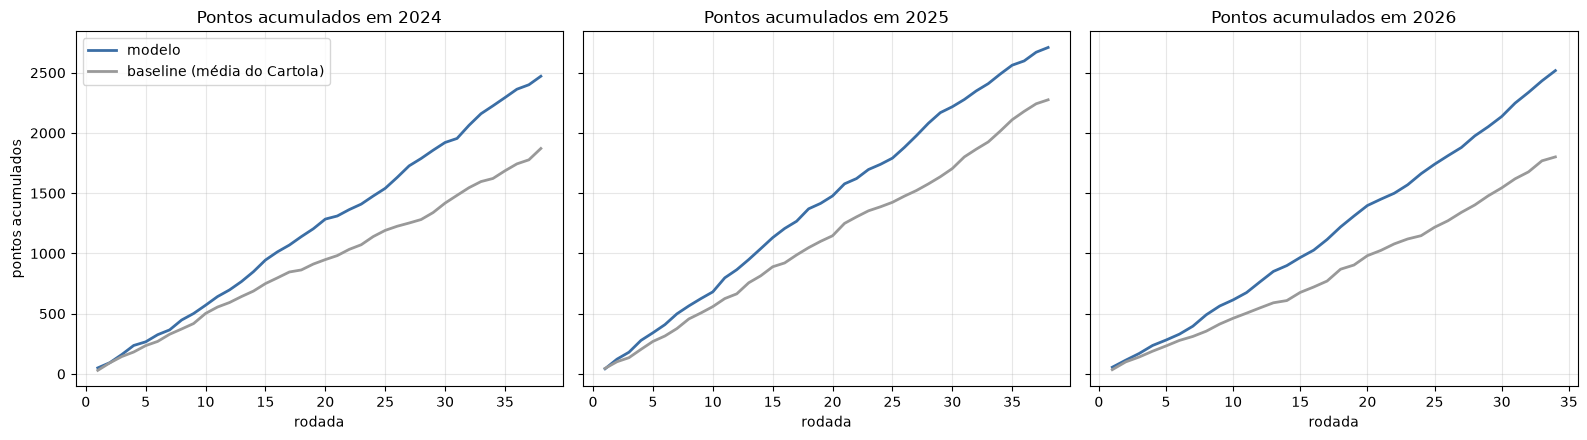

In [22]:
#Gráfico dos pontos acumulados rodada a rodada, modelo e baseline, em cada temporada
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
cores = {"modelo": "#3b6ea5", "baseline (média do Cartola)": "#999999"}

for j, ano in enumerate((2024, 2025, 2026)):
    for nome in ESTRATEGIAS:
        h = hist[(hist["estrategia"] == nome) & (hist["ano"] == ano)].sort_values("rodada")
        ax[j].plot(h["rodada"], h["pontos"].cumsum(), color=cores[nome], lw=2, label=nome)
    ax[j].set(title=f"Pontos acumulados em {ano}", xlabel="rodada")
    ax[j].grid(alpha=0.3)

ax[0].set_ylabel("pontos acumulados")
ax[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

O modelo faz 65,0, 71,3 e 74,1 pontos por rodada em 2024, 2025 e 2026, contra 49,3, 59,9 e 53,0 do baseline, ou seja, de 11 a 21 pontos a mais por rodada. A tabela e o gráfico de pontos acumulados mostram que a vantagem já existe na rodada 10 de cada temporada e cresce de forma contínua até o fim, nas três temporadas. As piores rodadas do modelo também são menos ruins: a média das 10% piores rodadas é de 31,6, 40,1 e 47,5 pontos, contra 24,7, 32,9 e 26,1 do baseline.

O modelo escala de 35 a 44 titulares que não jogam por temporada, contra 54 a 71 do baseline; com os reservas, sobram de 7 a 10 titulares zerados, contra 15 a 22. A média do Cartola não capta quem deixou de jogar, enquanto o modelo, que tem a disponibilidade recente entre os atributos, capta parte disso.

O patrimônio é um resultado misto. O modelo termina 2024 e 2026 melhor (C$ 99,3 e 121,1, contra 86,1 e 95,8), mas o baseline termina 2025 melhor (C$ 118,5 contra 96,8). A escalação busca apenas pontos, e o patrimônio é uma consequência.

## 9.4 Análise de erros
Primeiro, a qualidade da previsão em cada fase da temporada.

In [23]:
#Qualidade da previsão por fase da temporada, sem o filtro de rodadas da função avaliar
aval = c.merge(prev, on=["ano", "rodada", "atleta_id"])


def avaliar_fase(d, col):
    sp, top = [], []
    for _, rod in d.groupby(["ano", "rodada"]):
        sp.append(rod[col].rank().corr(rod["pontos_esc"].rank()))
        top.append(rod.nlargest(11, col)["pontos_esc"].mean())
    return {"Spearman": pd.Series(sp).mean(), "Top-11": pd.Series(top).mean()}


fases = {"rodadas 1–3": aval["rodada"] <= 3, "rodadas 4–8": aval["rodada"].between(4, 8), "rodadas 9–38": aval["rodada"] >= 9}
linhas = []
for fase, msk in fases.items():
    for metodo, col in [("modelo", "pred"), ("baseline", "prev_media")]:
        linhas.append({"fase": fase, "método": metodo, **avaliar_fase(aval[msk], col)})

pd.DataFrame(linhas).pivot(index="fase", columns="método", values=["Spearman", "Top-11"]).round(3)

Spearman          Top-11       
método       baseline modelo baseline modelo
fase                                        
rodadas 1–3     0.145  0.235    4.302  5.044
rodadas 4–8     0.176  0.258    4.648  5.792
rodadas 9–38    0.212  0.258    5.562  6.297

A previsão é mais difícil no começo da temporada (Spearman de 0,235 nas rodadas 1 a 3, contra 0,258 depois), porque ainda não há jogos na temporada, os elencos mudaram e, na primeira rodada, o status vem emprestado. Mesmo assim, o modelo é muito melhor que o baseline justamente nessa fase (0,235 contra 0,145), porque usa o histórico ponderado da temporada anterior, enquanto a média do Cartola recomeça do zero.

Em seguida, o erro nos clubes que acabaram de subir para a Série A.

In [24]:
#Erro médio da previsão (previsto menos real) nas 8 primeiras rodadas, separando os clubes promovidos
inicio_temp = aval[aval["rodada"] <= 8].assign(erro=lambda d: d["pred"] - d["pontos_esc"])

pd.DataFrame({"erro médio (previsto − real), rodadas 1–8": inicio_temp.groupby("promovido")["erro"].mean(),
              "linhas": inicio_temp.groupby("promovido").size()}).rename(index={0.0: "demais clubes", 1.0: "promovidos"}).round(3)

,"erro médio (previsto − real), rodadas 1–8",linhas
promovido,,
demais clubes,-0.131,4227
promovidos,-0.332,957


Nas oito primeiras rodadas, o modelo subestima os atletas de clubes promovidos (erro médio de -0,33 ponto, contra -0,13 dos demais). Isso é efeito da decisão de tratar os promovidos como fracos, com Elo inicial baixo e estatísticas antigas apagadas. É um viés conhecido: alguns promovidos começam bem, e o modelo demora a reconhecer.

Por fim, os titulares que não jogaram.

In [25]:
#Titulares escalados que não jogaram, quantos foram cobertos por reservas e quantos ficaram zerados
res.pivot_table(index="estratégia", columns="temporada",
                values=["titulares ausentes", "cobertos por reserva", "titulares zerados"]).astype(int)

cobertos por reserva           titulares ausentes           titulares zerados          
temporada                                   2024 2025 2026               2024 2025 2026              2024 2025 2026
estratégia                                                                                                         
baseline (média do Cartola)                   37   49   42                 54   71   57                17   22   15
modelo                                        33   36   28                 43   44   35                10    8    7

Mesmo com o modelo, de 35 a 44 titulares por temporada não jogam, cerca de um por rodada. Essa é a consequência direta do problema descrito na seção 3.5: o status usado é o do momento em que o mercado reabriu, e não o do fechamento. Os reservas cobrem cerca de 75% dessas ausências.

## 9.5 Resultados negativos
Durante o desenvolvimento, outras ideias foram testadas e retiradas por não melhorarem os resultados de forma consistente em quatro temporadas. Atributos sobre a ausência de companheiros de time (se um atleta rende mais quando certo companheiro falta) não trouxeram ganho. A medida de parcerias por RAPM, que estima o efeito de jogar junto com cada companheiro, ficou dentro do ruído e foi descartada. Atributos de carreira, com o histórico longo do atleta, não acrescentaram nada além das médias ponderadas.

Também se observou que uma única temporada simulada é ruidosa: pequenas mudanças nas escolhas iniciais alteram o patrimônio e todas as escalações seguintes. Por isso as conclusões se apoiam em diferenças grandes e consistentes nas três temporadas, e não em décimos de ponto.

## 9.6 Experimento complementar: o valor da informação de antes da rodada
Para estimar quanto a falta de informação de antes da rodada (seção 3.5) custa ao modelo, foi feito um experimento à parte, fora deste notebook, numa cópia do código final. Nele, o status de cada atleta foi substituído por versões com mais informação, e todo o processo (atributos, modelo e simulação) foi refeito.

No primeiro cenário, um oráculo informa exatamente quem vai jogar a rodada. É uma informação perfeita, que nenhum cartoleiro tem, e serve como teto: com ela o modelo fez 71,7, 83,5 e 79,9 pontos por rodada em 2024, 2025 e 2026, ou 78,3 na média, contra 70,1 com o status atual, e nenhum titular escalado deixou de jogar. É o maior ganho observado em todo o trabalho, maior que o de qualquer grupo de atributos, o que mostra o peso de ter a informação atualizada. O baseline não melhorou com o oráculo (53,5 pontos por rodada, contra 54,0), então o ganho vem da capacidade do modelo de usar a informação.

No segundo cenário, mais modesto, cada atleta revela sua disponibilidade verdadeira com uma chance que depende do status visto pela máquina, e, se não revelar, mantém esse status: 95% para suspensos (a suspensão é conhecida antes da rodada), 65% para prováveis, 55% para contundidos, 50% para dúvidas e 15% para nulos, já que a entrada de reservas raramente é prevista. Com isso, entre 2024 e 2026, a parcela de candidatos que realmente jogaram subiu de 84,6% para 94,2%, e a de prováveis que jogaram, de 85,9% para 95,3%; as dúvidas caíram de 18,9 para 9,3 por rodada e os suspensos, de 11,9 para 0,6. Repetido com 10 sorteios diferentes, esse cenário fez 67,9, 76,0 e 76,4 pontos por rodada (73,4 na média, com desvio de 1,5 entre os sorteios), e os titulares ausentes caíram de 35 a 44 para 11 a 18 por temporada.

Esses resultados não são confiáveis como medida real. As chances de revelação foram definidas pelo autor, sem nenhuma fonte que as comprove, e a informação simulada é construída a partir do resultado verdadeiro da rodada. O experimento serve apenas para indicar que mesmo um incremento simples na informação disponível antes da rodada gera um ganho grande, cerca de 40% do ganho do oráculo, e que coletar o mercado no momento do fechamento é o próximo passo mais promissor; ele não mostra quanto o modelo ganharia de fato.

# 10. Conclusões
A resposta à pergunta de pesquisa é sim. Usando apenas os dados públicos do Cartola, o modelo, que combina o LightGBM com a programação inteira, escala times que fazem 65,0, 71,3 e 74,1 pontos por rodada em 2024, 2025 e 2026, contra 49,3, 59,9 e 53,0 do baseline que escala pela média do Cartola. São de 11 a 21 pontos a mais por rodada, e a vantagem se mantém no holdout de 2026. Na previsão, o modelo supera o baseline em todos os períodos, no Top-11, no Spearman e no MAE.

As principais contribuições estão no tratamento dos dados e na engenharia de atributos: a correção dos arquivos corrompidos e a reconstrução das rodadas perdidas, a remoção do vazamento dos dados de depois da rodada, a inferência do adversário, da titularidade e do cobrador de pênalti apenas com os dados do Cartola, e a simulação completa da temporada, com orçamento que muda a cada rodada e reservas.

A principal limitação é o uso de dados de depois da rodada: a máquina escala com o status do momento em que o mercado reabriu, e não com o do fechamento, e por isso escala cerca de um titular por rodada que não joga, uma informação que um cartoleiro atento teria. O experimento complementar da seção 9.6 indica que essa informação vale vários pontos por rodada, mas, por depender de probabilidades estimadas pelo autor, o número exato não é confiável. Além disso, o status da primeira rodada é emprestado da segunda em cinco temporadas; faltam informações como minutos jogados, escalações, notícias e estatísticas avançadas, e a titularidade, o adversário e o cobrador de pênalti são inferidos, com algum erro; as regras de capitão e reservas são simplificadas; cada temporada é simulada uma única vez, então os números devem ser lidos como ordem de grandeza; e a regra de preço e a escala de pontuação mudam entre temporadas.

Entre os vieses, o modelo subestima os atletas de clubes recém-promovidos no início da temporada, e até 2022 a informação de quem entrou em campo é inferida, com 99,8% de acerto onde há gabarito. Quanto aos riscos, o Cartola é um jogo, mas o mesmo tipo de modelo pode ser usado em apostas esportivas, em que o erro tem custo financeiro; as previsões têm incerteza alta e não devem ser tratadas como garantia.

Como próximos passos, o mais importante é coletar o mercado no momento do fechamento, e não só na reabertura, para ter o status real de antes da rodada e atacar a principal limitação do trabalho. Também seria possível incorporar fontes abertas de escalações e minutos jogados quando houver cobertura do Brasileirão e simular cada temporada várias vezes para medir a incerteza dos resultados.